# Offline English Wikipedia RAG with Flan-T5-small

**A self-contained notebook:** download the complete English Wikipedia subset once, index a local
slice, retrieve passages with BM25, and generate short answers with a local Flan-T5-small model.
All project code, download manifests, and evaluation questions are included here. No separate
Python implementation files are required.

Compare **k = 1, 3, 5** retrieved passages using **concatenate** and **generate-from-evidence** fusion.
A closed-book baseline measures performance without retrieval. Answers include source passages
and URLs; a lexical support guard rejects answers absent from the visible evidence.

### First run and offline reuse
1. Select a Python 3.11–3.13 Jupyter kernel. Review the paths and settings below, then run all cells.
2. The first run installs missing packages and downloads the **complete English `20231101.en`
   subset: all 41 Parquet files, about 11.63 GB**. Other language subsets are excluded.
   The original dataset card and repository metadata are also retained.
3. Flan-T5-small weights and tokenizer add about **311 MB**. The initial index uses the first
   **500 English articles**, stored as about **12.9 MB** of JSONL plus a **38 MB** search index.
   `INDEX_ARTICLES` can be increased without downloading the English dataset again.
4. Later runs validate and reuse local files **without contacting Hugging Face**. Set
   `ALLOW_DOWNLOADS = False` to require an entirely offline run after initial setup.
5. Change `QUESTION`, then rerun the retrieval and answer cells. All evaluation runs locally.

Allow roughly **13–15 GB free disk space**, plus the Python environment, for the dataset, model,
small index, results, and temporary download space. Increasing the indexed article count needs more.
Sizes use decimal GB/MB. The 71.79 GB multilingual repository is **not** downloaded by this notebook.

Source: [wikimedia/wikipedia](https://huggingface.co/datasets/wikimedia/wikipedia), pinned revision
`b04c8d1ceb2f5cd4588862100d08de323dccfbaa`. The 500-article slice and 28-question development set
are small convenience samples; their results do not represent all English Wikipedia.

Setup verifies the complete English download locally and reuses it when present. Missing files
are acquired only when downloads are enabled.


**Retrieval assessment (23 October 2026): BM25 retained.** A local MiniLM + FAISS candidate was
compared against BM25 using 48 questions and all six fusion/retrieval-size settings. It did not meet
the rule for replacing BM25. Section 11 records the measurements, uncertainty, and decision.
The active RAG pipeline therefore continues to use BM25 and needs no embedding-model or FAISS download.


## 1. Configuration and Git exclusions

The project directory is `/Users/amolsingh/Documents/code/IITB-DL`. Change `PROJECT_DIR` when moving
the notebook to another computer. `DATASET_DIR` may point to an existing complete English snapshot
with the layout `20231101.en/train-*.parquet` and the retained dataset README/metadata.

`ALLOW_DOWNLOADS=True` permits acquisition and repair of missing or invalid files. Complete files
are skipped. `VERIFY_DATASET_HASHES=True` additionally hashes every dataset file; the default checks
each pinned filename and size, which cannot detect same-size corruption. The model and extracted
corpus are always hash-checked. `INDEX_ARTICLES` controls indexing only, never download size.

The next cell writes `.gitignore` before downloads. Local data, models, caches, indexes, results,
and notebook checkpoints stay out of Git; the notebook stays trackable. Ignore rules cannot untrack
previously committed files, so the cell stops if it detects tracked local assets.


In [36]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from collections import Counter
from contextlib import contextmanager
from uuid import uuid4
import copy
import csv
import hashlib
import importlib.metadata
import importlib.util
import itertools
import json
import os
import platform
import re
import shutil
import socket
import sqlite3
import statistics
import string
import subprocess
import sys
import tempfile
import time
from unittest import mock

PROJECT_DIR = Path("/Users/amolsingh/Documents/code/IITB-DL")
ROOT = Path(PROJECT_DIR).expanduser().resolve() if PROJECT_DIR is not None else Path.cwd().resolve()
DATASET_DIR = ROOT / "data" / "wikipedia_snapshot"
DOWNLOAD_SCOPE = "english"  # The complete English subset only.
MODEL_DIR = ROOT / "models" / "flan-t5-small"
NOTEBOOK_NAME = "offline_wikipedia_rag.ipynb"
ALLOW_DOWNLOADS = True
INSTALL_MISSING_PACKAGES = True
VERIFY_DATASET_HASHES = False
DOWNLOAD_WORKERS = 4
INDEX_ARTICLES = 500  # Limits the English index only, never the complete English download.
REBUILD_CORPUS = False
REBUILD_INDEX = False
QUESTION = "What is the atomic number of aluminium?"
K = 3
KS = [1, 3, 5]
RUN_FULL_ABLATION = True
DEVICE = "cpu"
THREADS = 4
MAX_INPUT_TOKENS = 512
MAX_NEW_TOKENS = 48

DATASET = "wikimedia/wikipedia"
DATASET_REVISION = "b04c8d1ceb2f5cd4588862100d08de323dccfbaa"
CONFIG = "20231101.en"
MODEL = "google/flan-t5-small"
MODEL_REVISION = "0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab"
ROOT.mkdir(parents=True, exist_ok=True)
print("Working directory:", ROOT)
print("Complete English download:", DATASET_DIR)
print("Python:", sys.executable)

if DOWNLOAD_SCOPE != "english":
    raise ValueError("This notebook downloads the English subset only.")
if not isinstance(INDEX_ARTICLES, int) or INDEX_ARTICLES < 500:
    raise ValueError("Use at least 500 articles for the embedded evaluation questions.")


Working directory: /Users/amolsingh/Documents/code/IITB-DL
Complete English download: /Users/amolsingh/Documents/code/IITB-DL/data/wikipedia_snapshot
Python: /opt/homebrew/Caskroom/miniforge/base/bin/python


In [37]:
GITIGNORE_RULES = '# Offline RAG: local assets and generated runs must stay out of Git.\n/data/\n/models/\n/results/\n/.cache/\n/.venv/\n/venv/\n**/.ipynb_checkpoints/\n**/__pycache__/\n.DS_Store\n'
ignore_path = ROOT / ".gitignore"
existing_rules = ignore_path.read_text(encoding="utf-8") if ignore_path.exists() else ""
if GITIGNORE_RULES.strip() not in existing_rules:
    with ignore_path.open("a", encoding="utf-8") as handle:
        handle.write(("\n" if existing_rules else "") + GITIGNORE_RULES)
if shutil.which("git"):
    tracked = subprocess.run(
        ["git", "-C", str(ROOT), "ls-files", "--", "data", "models", "results", ".cache"],
        capture_output=True, text=True,
    )
    if tracked.returncode == 0 and tracked.stdout.strip():
        raise RuntimeError("Local assets are already tracked by Git. Review and untrack them "
                           "before proceeding:\n" + tracked.stdout)
print("Git exclusions ready:", ignore_path)


Git exclusions ready: /Users/amolsingh/Documents/code/IITB-DL/.gitignore


### Install third-party packages if needed

There is no external `requirements.txt` dependency. This cell installs only packages absent from the
selected kernel, and only when downloads are enabled. Already installed packages are retained.
The listed versions match the tested implementation; their installed versions are recorded per run.

The package versions below are the tested versions. Existing installations are reused; the final run manifest records their actual versions. Restart the kernel if packages were changed after importing them.


In [38]:
PACKAGE_REQUIREMENTS = {
    "torch": "torch==2.9.0",
    "transformers": "transformers==4.57.1",
    "huggingface_hub": "huggingface-hub==0.36.2",
    "sentencepiece": "sentencepiece==0.2.1",
    "pyarrow": "pyarrow==26.0.0",
    "numpy": "numpy==2.5.4",
    "pandas": "pandas==3.0.6",
    "matplotlib": "matplotlib==3.10.7",
}
missing = [requirement for name, requirement in PACKAGE_REQUIREMENTS.items()
           if importlib.util.find_spec(name) is None]
if missing:
    if not (INSTALL_MISSING_PACKAGES and ALLOW_DOWNLOADS):
        raise RuntimeError("Install these packages while online: " + ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required Python packages are already installed; installation skipped.")

import pandas as pd
from IPython.display import Image, Markdown, display


All required Python packages are already installed; installation skipped.


## 2. Embedded provenance and evaluation data

The pinned English file inventory below records the name, byte size, and content hash of all
41 English Parquet shards and the dataset README/metadata. The model inventory and all 28
evaluation questions are also embedded. No inventory or question file needs to be fetched separately.
Only these English paths can be passed to the dataset downloader.


In [39]:
EMBEDDED_INVENTORY = {'schema_version': 1,
 'dataset': {'repo_id': 'wikimedia/wikipedia',
             'repo_type': 'dataset',
             'revision': 'b04c8d1ceb2f5cd4588862100d08de323dccfbaa',
             'files': [{'path': '.gitattributes',
                        'size': 2307,
                        'git_sha1': '28df5f900b358436f0267334b3e3e9af33f917ba'},
                       {'path': '20231101.en/train-00000-of-00041.parquet',
                        'size': 420296449,
                        'sha256': '382e7f6f09e488b24793a7f7cfc659879d5a22da2cf2efec6491665f0c019677'},
                       {'path': '20231101.en/train-00001-of-00041.parquet',
                        'size': 351448367,
                        'sha256': '6cd57a5825312ca966313d4a1b614690b5c4fb53cee9b124bc0e999977eb36cf'},
                       {'path': '20231101.en/train-00002-of-00041.parquet',
                        'size': 329024669,
                        'sha256': 'b18674f163d4f106e43396fd58412a79b80a418c72bb728c20af439e7ca4d5b7'},
                       {'path': '20231101.en/train-00003-of-00041.parquet',
                        'size': 330779424,
                        'sha256': '0b8a6f452f5ef59d0986a067f70110feb16d7c1d281ba2db0b3df32933618fcc'},
                       {'path': '20231101.en/train-00004-of-00041.parquet',
                        'size': 306945391,
                        'sha256': '1424300f113c13ee022b7929185fa4f7e20c6195ba563d728e8a3dc47c8e9aba'},
                       {'path': '20231101.en/train-00005-of-00041.parquet',
                        'size': 243974056,
                        'sha256': '220d31bb222ba2d449c845733622a6a2b7a89db3e28b24bfcb3a9bb3e52c6c8d'},
                       {'path': '20231101.en/train-00006-of-00041.parquet',
                        'size': 266288728,
                        'sha256': 'b8becbe9989a2c63f129a707a4674a84fb093c163673b1f4ce97afbf5306f04c'},
                       {'path': '20231101.en/train-00007-of-00041.parquet',
                        'size': 228195804,
                        'sha256': 'adebba8b075444923ba42ed6214fe205efc756c773f440d98cbdd88a33597c2c'},
                       {'path': '20231101.en/train-00008-of-00041.parquet',
                        'size': 247687191,
                        'sha256': '905f959921ab8de07e7ce238d7c9ef33bd597585a17a99c3ba00163b25002bef'},
                       {'path': '20231101.en/train-00009-of-00041.parquet',
                        'size': 227378231,
                        'sha256': '465bd99719b0f2d1974402b7922a7a66399675dc6218a0a40057e0512592c07b'},
                       {'path': '20231101.en/train-00010-of-00041.parquet',
                        'size': 233604795,
                        'sha256': 'cd8b4e9ee2506ba5f47d552c56e2a7569402a6814d9fa171c0e995e56859e51b'},
                       {'path': '20231101.en/train-00011-of-00041.parquet',
                        'size': 231748583,
                        'sha256': '881e8efe6dbaddd34791fdc2158123ed344c436263b9052a0d659418fff89c3a'},
                       {'path': '20231101.en/train-00012-of-00041.parquet',
                        'size': 239222511,
                        'sha256': 'd33835c5e69d5f2464cab1ad70b998ec37e084ea0c0ef9f837fac4a9bb030860'},
                       {'path': '20231101.en/train-00013-of-00041.parquet',
                        'size': 241146961,
                        'sha256': '9abcab8c808952dc6a4822da1591db51de980a792ed37acd3bd243ebd99d200e'},
                       {'path': '20231101.en/train-00014-of-00041.parquet',
                        'size': 222798405,
                        'sha256': '7419912e150b17ce395ea039620c21a7e1cb54731c7c2fd2ccbbed56674eeccd'},
                       {'path': '20231101.en/train-00015-of-00041.parquet',
                        'size': 234578705,
                        'sha256': '1d11ff44d5579dbb9e1976330cdf70ec8b04a7a5dfe4113916b71551fb3cf715'},
                       {'path': '20231101.en/train-00016-of-00041.parquet',
                        'size': 503153575,
                        'sha256': 'e559da89b795e365bc1d1bb87576d1a5478c346cf37eb06159caf9579fe1e54e'},
                       {'path': '20231101.en/train-00017-of-00041.parquet',
                        'size': 230813705,
                        'sha256': '216cd1e4921cc884ebdaed94b61d3e15560f502f73752f3694ed05e6347a6562'},
                       {'path': '20231101.en/train-00018-of-00041.parquet',
                        'size': 231055386,
                        'sha256': '64fb53939ab6aae24299cdafa2ce88e115d91930be35609b2dcfc1fc3b9f85eb'},
                       {'path': '20231101.en/train-00019-of-00041.parquet',
                        'size': 195276969,
                        'sha256': '99c23125b0dd115d68f4a921376880e307bdfcbf3bfd66ae4ed90e853e1dadac'},
                       {'path': '20231101.en/train-00020-of-00041.parquet',
                        'size': 225141733,
                        'sha256': '79ee06627f4ba2fec056fcd23c077a29238bbcbacc3187e8d1a0b47e663e9c7a'},
                       {'path': '20231101.en/train-00021-of-00041.parquet',
                        'size': 216445587,
                        'sha256': 'e9f695672d916793439d8f48893ecde94c61b0eb038a0034c4e1f1f194205979'},
                       {'path': '20231101.en/train-00022-of-00041.parquet',
                        'size': 201995404,
                        'sha256': '50ba80435bf2fd0b818533a1ca3118454a3ae275dc2250e0b68dc852dd03f3d2'},
                       {'path': '20231101.en/train-00023-of-00041.parquet',
                        'size': 212615391,
                        'sha256': 'b722b7e4039c65382286b6aa5a35f9a4c5d3536b758c346a94af7a2a692cc6bb'},
                       {'path': '20231101.en/train-00024-of-00041.parquet',
                        'size': 220729597,
                        'sha256': 'eb9818bff41110829f39f8100aee5936cf6088c72a5925c2b08bcd3c37ac0170'},
                       {'path': '20231101.en/train-00025-of-00041.parquet',
                        'size': 221292721,
                        'sha256': 'fed7d34add9b161745dd2677ff3c5f782a471f433bae80c59933e9b68225be93'},
                       {'path': '20231101.en/train-00026-of-00041.parquet',
                        'size': 208188233,
                        'sha256': 'ffffb7d303ef78b47c4c835211b35f6052ffa2d5998e3f65d69bb7fe512ee69c'},
                       {'path': '20231101.en/train-00027-of-00041.parquet',
                        'size': 213980716,
                        'sha256': '1f0c7bcaf2aeb9765a981c8911b95ab3a9e50456bbad64e50e722a53b8608ccc'},
                       {'path': '20231101.en/train-00028-of-00041.parquet',
                        'size': 188376392,
                        'sha256': '10589a39188af404fa458da252df7dcf22c6f6395a1501d9243ef56ce4c3c148'},
                       {'path': '20231101.en/train-00029-of-00041.parquet',
                        'size': 217775627,
                        'sha256': '8f24c4250d69dbee36962d587cac632098635fa78e8705db140cce68928bb9d3'},
                       {'path': '20231101.en/train-00030-of-00041.parquet',
                        'size': 203945186,
                        'sha256': '1de329963a4aaed0c40d820a564487dc98ef113c8ca6b88b11d495d6a4b98774'},
                       {'path': '20231101.en/train-00031-of-00041.parquet',
                        'size': 215470925,
                        'sha256': '55e58e33710b9326e1ce3aab1319377afd9ce18df089b08aba2ab9286228666e'},
                       {'path': '20231101.en/train-00032-of-00041.parquet',
                        'size': 214242576,
                        'sha256': '354c4d35fa089351ed4ec1622fd8930f309dddd3dccbf411e4dd8a52eff638d4'},
                       {'path': '20231101.en/train-00033-of-00041.parquet',
                        'size': 202706223,
                        'sha256': 'a5140a1c80805d599b791fbd668d0f49972eecf0cd2d863cede53013f52e0900'},
                       {'path': '20231101.en/train-00034-of-00041.parquet',
                        'size': 219010799,
                        'sha256': '298528554e93a3fae9f694087a7376b70be223084b2739ef9488418202a948ab'},
                       {'path': '20231101.en/train-00035-of-00041.parquet',
                        'size': 224459876,
                        'sha256': '460ab2f5a2da091e310d0f86c461a73f22b189f22ac7115e4708a5da9baf4d1c'},
                       {'path': '20231101.en/train-00036-of-00041.parquet',
                        'size': 610276598,
                        'sha256': '7385c9f0482cd592578c1c22c5eaaad8bc3013bec4e3bfe394b441dc728f78a9'},
                       {'path': '20231101.en/train-00037-of-00041.parquet',
                        'size': 674143674,
                        'sha256': 'f2f7718efc3165ed599ec0d99fef07b98ec4dd0da902ffc330dd5c75016240cb'},
                       {'path': '20231101.en/train-00038-of-00041.parquet',
                        'size': 538231796,
                        'sha256': '16ff05ab829cb9c983db14b7f77a677d279f8120571e67b2793735851b71ae89'},
                       {'path': '20231101.en/train-00039-of-00041.parquet',
                        'size': 464851854,
                        'sha256': '63a0be9b1b458b834428c897e37a6e2643e0c33dd4ac08a994f3b3dbeee124e1'},
                       {'path': '20231101.en/train-00040-of-00041.parquet',
                        'size': 421630218,
                        'sha256': 'fed6addb1da9364fcf42c6953539eecc21bbc2cf3cd33743684e6872ce6c468a'},
                       {'path': 'README.md',
                        'size': 130835,
                        'git_sha1': '20cd0049340ebfdf4512171270e3b6ae71a25e8d'}],
             'total_bytes': 11631062173},
 'model': {'repo_id': 'google/flan-t5-small',
           'repo_type': 'model',
           'revision': '0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab',
           'files': [{'path': 'README.md',
                      'size': 10820,
                      'git_sha1': '245f4a935cf3b2c65ed3d0c1a11b15fd6ab43b80'},
                     {'path': 'config.json',
                      'size': 1401,
                      'git_sha1': '360a0073f29a105ced4a366cda27e668b11bb73b'},
                     {'path': 'generation_config.json',
                      'size': 147,
                      'git_sha1': 'd52815623b46b7db1c4b957b5a83a8ad30b0146a'},
                     {'path': 'model.safetensors',
                      'size': 307867048,
                      'sha256': '495fa51e204676f1a857a9fc13c4c89f3f5ba9f480b898cebca02add25e6d749'},
                     {'path': 'special_tokens_map.json',
                      'size': 2201,
                      'git_sha1': '2c19eb6e3b583f52d34b903b5978d3d30b6b7682'},
                     {'path': 'spiece.model',
                      'size': 791656,
                      'sha256': 'd60acb128cf7b7f2536e8f38a5b18a05535c9e14c7a355904270e15b0945ea86'},
                     {'path': 'tokenizer.json',
                      'size': 2424064,
                      'git_sha1': 'fc669fbad1a6a82119ca3e1fa75db33ee22ca47d'},
                     {'path': 'tokenizer_config.json',
                      'size': 2539,
                      'git_sha1': 'db13bf98b7714acc4dea7621ff7f4ab93f64258e'}],
           'total_bytes': 311099876}}

EVAL_QUESTIONS = [{'id': 'q01',
  'question': 'What is the atomic number of aluminium?',
  'answerable': True,
  'answers': ['13'],
  'article_id': '904',
  'source_title': 'Aluminium',
  'source_url': 'https://en.wikipedia.org/wiki/Aluminium',
  'evidence_quote': 'is a chemical element with the symbol\xa0Al and atomic '
                    'number\xa013',
  'gold_passage_ids': ['904:0']},
 {'id': 'q02',
  'question': 'What is the capital of Alabama?',
  'answerable': True,
  'answers': ['Montgomery'],
  'article_id': '303',
  'source_title': 'Alabama',
  'source_url': 'https://en.wikipedia.org/wiki/Alabama',
  'evidence_quote': "Alabama's capital is Montgomery",
  'gold_passage_ids': ['303:0', '303:1']},
 {'id': 'q03',
  'question': 'In which city was Aristotle born?',
  'answerable': True,
  'answers': ['Stagira'],
  'article_id': '308',
  'source_title': 'Aristotle',
  'source_url': 'https://en.wikipedia.org/wiki/Aristotle',
  'evidence_quote': 'He was born in the city of Stagira in northern Greece '
                    'during the Classical period',
  'gold_passage_ids': ['308:0']},
 {'id': 'q04',
  'question': 'What philosophical system did Ayn Rand develop?',
  'answerable': True,
  'answers': ['Objectivism'],
  'article_id': '339',
  'source_title': 'Ayn Rand',
  'source_url': 'https://en.wikipedia.org/wiki/Ayn%20Rand',
  'evidence_quote': 'developing a philosophical system she named Objectivism',
  'gold_passage_ids': ['339:0']},
 {'id': 'q05',
  'question': 'What is the capital of Algeria?',
  'answerable': True,
  'answers': ['Algiers'],
  'article_id': '358',
  'source_title': 'Algeria',
  'source_url': 'https://en.wikipedia.org/wiki/Algeria',
  'evidence_quote': 'The capital and largest city is Algiers',
  'gold_passage_ids': ['358:1']},
 {'id': 'q06',
  'question': 'How many code points does ASCII have?',
  'answerable': True,
  'answers': ['128'],
  'article_id': '586',
  'source_title': 'ASCII',
  'source_url': 'https://en.wikipedia.org/wiki/ASCII',
  'evidence_quote': 'ASCII has just 128 code points',
  'gold_passage_ids': ['586:0']},
 {'id': 'q07',
  'question': 'What is the official language of Andorra?',
  'answerable': True,
  'answers': ['Catalan'],
  'article_id': '600',
  'source_title': 'Andorra',
  'source_url': 'https://en.wikipedia.org/wiki/Andorra',
  'evidence_quote': 'The official language is Catalan',
  'gold_passage_ids': ['600:1', '600:2']},
 {'id': 'q08',
  'question': 'Who wrote Animal Farm?',
  'answerable': True,
  'answers': ['George Orwell', 'Orwell'],
  'article_id': '620',
  'source_title': 'Animal Farm',
  'source_url': 'https://en.wikipedia.org/wiki/Animal%20Farm',
  'evidence_quote': 'by George Orwell, first published in England on 17 August '
                    '1945',
  'gold_passage_ids': ['620:0']},
 {'id': 'q09',
  'question': 'What is the state capital of Alaska?',
  'answerable': True,
  'answers': ['Juneau'],
  'article_id': '624',
  'source_title': 'Alaska',
  'source_url': 'https://en.wikipedia.org/wiki/Alaska',
  'evidence_quote': 'The state capital of Juneau is the second-largest city in '
                    'the United States by area',
  'gold_passage_ids': ['624:1', '624:2']},
 {'id': 'q10',
  'question': 'In which English town was Aldous Huxley born?',
  'answerable': True,
  'answers': ['Godalming'],
  'article_id': '628',
  'source_title': 'Aldous Huxley',
  'source_url': 'https://en.wikipedia.org/wiki/Aldous%20Huxley',
  'evidence_quote': 'Huxley was born in Godalming, Surrey, England, in 1894',
  'gold_passage_ids': ['628:2']},
 {'id': 'q11',
  'question': 'Who piloted the Command Module Columbia during Apollo 11?',
  'answerable': True,
  'answers': ['Michael Collins', 'Collins'],
  'article_id': '662',
  'source_title': 'Apollo 11',
  'source_url': 'https://en.wikipedia.org/wiki/Apollo%2011',
  'evidence_quote': 'pilot Michael Collins flew the Command Module Columbia in '
                    'lunar orbit',
  'gold_passage_ids': ['662:1']},
 {'id': 'q12',
  'question': "Approximately what percentage of Earth's surface does the "
              'Atlantic Ocean cover?',
  'answerable': True,
  'answers': ['17%', '17 percent', '17'],
  'article_id': '698',
  'source_title': 'Atlantic Ocean',
  'source_url': 'https://en.wikipedia.org/wiki/Atlantic%20Ocean',
  'evidence_quote': "It covers approximately 17% of Earth's surface",
  'gold_passage_ids': ['698:0']},
 {'id': 'q13',
  'question': 'In which year did Albert Einstein receive the Nobel Prize in '
              'Physics?',
  'answerable': True,
  'answers': ['1921'],
  'article_id': '736',
  'source_title': 'Albert Einstein',
  'source_url': 'https://en.wikipedia.org/wiki/Albert%20Einstein',
  'evidence_quote': 'He received the 1921 Nobel Prize in Physics',
  'gold_passage_ids': ['736:1']},
 {'id': 'q14',
  'question': 'What is the capital of Albania?',
  'answerable': True,
  'answers': ['Tirana'],
  'article_id': '738',
  'source_title': 'Albania',
  'source_url': 'https://en.wikipedia.org/wiki/Albania',
  'evidence_quote': 'Tirana is the capital and largest city in the country',
  'gold_passage_ids': ['738:1']},
 {'id': 'q15',
  'question': 'What is the capital of Azerbaijan?',
  'answerable': True,
  'answers': ['Baku'],
  'article_id': '746',
  'source_title': 'Azerbaijan',
  'source_url': 'https://en.wikipedia.org/wiki/Azerbaijan',
  'evidence_quote': 'Baku is the capital and largest city',
  'gold_passage_ids': ['746:0']},
 {'id': 'q16',
  'question': 'On what date did Ankara become the new Turkish capital?',
  'answerable': True,
  'answers': ['29 October 1923', 'October 29, 1923'],
  'article_id': '802',
  'source_title': 'Ankara',
  'source_url': 'https://en.wikipedia.org/wiki/Ankara',
  'evidence_quote': 'Ankara became the new Turkish capital upon the '
                    'establishment of the Republic on 29 October 1923',
  'gold_passage_ids': ['802:2', '802:3']},
 {'id': 'q17',
  'question': 'In which Dutch province is Amsterdam located?',
  'answerable': True,
  'answers': ['North Holland'],
  'article_id': '844',
  'source_title': 'Amsterdam',
  'source_url': 'https://en.wikipedia.org/wiki/Amsterdam',
  'evidence_quote': 'Located in the Dutch province of North Holland',
  'gold_passage_ids': ['844:0']},
 {'id': 'q18',
  'question': 'What explosive is Alfred Nobel most famous for inventing?',
  'answerable': True,
  'answers': ['dynamite'],
  'article_id': '851',
  'source_title': 'Alfred Nobel',
  'source_url': 'https://en.wikipedia.org/wiki/Alfred%20Nobel',
  'evidence_quote': "Nobel's most famous invention was dynamite",
  'gold_passage_ids': ['851:0']},
 {'id': 'q19',
  'question': 'In which city was Alexander Graham Bell born?',
  'answerable': True,
  'answers': ['Edinburgh'],
  'article_id': '852',
  'source_title': 'Alexander Graham Bell',
  'source_url': 'https://en.wikipedia.org/wiki/Alexander%20Graham%20Bell',
  'evidence_quote': 'Bell was born in Edinburgh, Scotland, on March 3, 1847',
  'gold_passage_ids': ['852:2']},
 {'id': 'q20',
  'question': 'To which continent is the aardvark native?',
  'answerable': True,
  'answers': ['Africa'],
  'article_id': '680',
  'source_title': 'Aardvark',
  'source_url': 'https://en.wikipedia.org/wiki/Aardvark',
  'evidence_quote': 'nocturnal mammal native to Africa',
  'gold_passage_ids': ['680:0']},
 {'id': 'q21',
  'question': "What does Euclid's algorithm compute for two integers?",
  'answerable': True,
  'answers': ['greatest common divisor',
              'greatest common divisor (GCD)',
              'GCD'],
  'article_id': '775',
  'source_title': 'Algorithm',
  'source_url': 'https://en.wikipedia.org/wiki/Algorithm',
  'evidence_quote': 'an efficient method for computing the greatest common '
                    'divisor (GCD) of two integers',
  'gold_passage_ids': ['775:41']},
 {'id': 'q22',
  'question': 'What type of rocket launched Apollo 11?',
  'answerable': True,
  'answers': ['Saturn V', 'Saturn V rocket'],
  'article_id': '662',
  'source_title': 'Apollo 11',
  'source_url': 'https://en.wikipedia.org/wiki/Apollo%2011',
  'evidence_quote': 'Apollo 11 was launched by a Saturn V rocket',
  'gold_passage_ids': ['662:1']},
 {'id': 'q23',
  'question': "In which year was Alfred Nobel's dynamite patented?",
  'answerable': True,
  'answers': ['1867'],
  'article_id': '851',
  'source_title': 'Alfred Nobel',
  'source_url': 'https://en.wikipedia.org/wiki/Alfred%20Nobel',
  'evidence_quote': 'dynamite, an explosive using  nitroglycerin; it was '
                    'patented in 1867',
  'gold_passage_ids': ['851:0']},
 {'id': 'q24',
  'question': 'What albedo value corresponds to a body that reflects all '
              'incident radiation?',
  'answerable': True,
  'answers': ['1', 'one'],
  'article_id': '39',
  'source_title': 'Albedo',
  'source_url': 'https://en.wikipedia.org/wiki/Albedo',
  'evidence_quote': '1 (corresponding to a body that reflects all incident '
                    'radiation',
  'gold_passage_ids': ['39:0']},
 {'id': 'q25',
  'question': 'Who won the Nobel Prize in Physics in 2024?',
  'answerable': False,
  'answers': [],
  'article_id': None,
  'source_title': None,
  'source_url': None,
  'evidence_quote': None,
  'gold_passage_ids': [],
  'unanswerable_reason': 'The question asks about an event after the November '
                         '2023 corpus snapshot.'},
 {'id': 'q26',
  'question': 'Which film won the Academy Award for Best Picture in 2024?',
  'answerable': False,
  'answers': [],
  'article_id': None,
  'source_title': None,
  'source_url': None,
  'evidence_quote': None,
  'gold_passage_ids': [],
  'unanswerable_reason': 'The question asks about an event after the November '
                         '2023 corpus snapshot.'},
 {'id': 'q27',
  'question': "Who won the Wimbledon men's singles title in 2024?",
  'answerable': False,
  'answers': [],
  'article_id': None,
  'source_title': None,
  'source_url': None,
  'evidence_quote': None,
  'gold_passage_ids': [],
  'unanswerable_reason': 'The question asks about an event after the November '
                         '2023 corpus snapshot.'},
 {'id': 'q28',
  'question': "What was Apple Inc.'s total revenue for fiscal year 2025?",
  'answerable': False,
  'answers': [],
  'article_id': None,
  'source_title': None,
  'source_url': None,
  'evidence_quote': None,
  'gold_passage_ids': [],
  'unanswerable_reason': 'The question asks about an event after the November '
                         '2023 corpus snapshot.'}]


In [40]:
def read_jsonl(path: Path) -> list[dict]:
    with path.open(encoding="utf-8") as stream:
        return [json.loads(line) for line in stream if line.strip()]

def write_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    temp.replace(path)

def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


## 3. Complete download, validation, and resume logic

The following functions are the actual implementation. They inspect every expected file before any
network call. The inline download worker runs in a fresh Python process so a prior offline model load
does not prevent a later permitted repair. Its complete code is shown in the cell; it does not read or
write a helper `.py` script.


In [41]:
def validate_inventory(spec):
    names = set()
    for entry in spec["files"]:
        name = PurePosixPath(entry["path"])
        if not name.parts or name.is_absolute() or ".." in name.parts or entry["path"] in names:
            raise ValueError("Invalid or duplicate inventory path")
        if not isinstance(entry["size"], int) or entry["size"] < 0:
            raise ValueError("Invalid inventory file size")
        if not (entry.get("sha256") or entry.get("git_sha1")):
            raise ValueError("Inventory entry lacks a content hash")
        names.add(entry["path"])
    if not names or sum(e["size"] for e in spec["files"]) != spec["total_bytes"]:
        raise ValueError("Incomplete inventory")
    return spec


def dataset_inventory():
    spec = validate_inventory(copy.deepcopy(EMBEDDED_INVENTORY["dataset"]))
    if (spec["repo_id"], spec["repo_type"], spec["revision"]) != (
        DATASET, "dataset", DATASET_REVISION
    ):
        raise ValueError("Expected the pinned wikimedia/wikipedia repository")
    shards = [entry for entry in spec["files"] if entry["path"].endswith(".parquet")]
    expected = {f"{CONFIG}/train-{i:05d}-of-00041.parquet" for i in range(41)}
    if {entry["path"] for entry in shards} != expected:
        raise ValueError("The inventory must contain all 41 English Parquet shards")
    if sum(entry["size"] for entry in shards) != 11630929031:
        raise ValueError("English download size does not match the pinned revision")
    if any("/" in entry["path"] and not entry["path"].startswith(CONFIG + "/")
           for entry in spec["files"]):
        raise ValueError("Non-English dataset paths are forbidden")
    return spec


In [42]:
def _file_valid(path: Path, entry: dict, verify_hashes: bool) -> bool:
    if not path.is_file() or path.stat().st_size != entry["size"]:
        return False
    if not verify_hashes:
        return True
    if "sha256" in entry:
        return sha256(path) == entry["sha256"]
    digest = hashlib.sha1(f'blob {entry["size"]}\0'.encode())
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest() == entry["git_sha1"]

def snapshot_status(destination: Path, spec: dict, verify_hashes=False) -> dict:
    missing = [entry for entry in spec["files"]
               if not _file_valid(destination / entry["path"], entry, verify_hashes)]
    return {
        "repo_id": spec["repo_id"], "repo_type": spec["repo_type"], "revision": spec["revision"],
        "total_files": len(spec["files"]), "valid_files": len(spec["files"]) - len(missing),
        "total_bytes": spec["total_bytes"], "missing_bytes": sum(e["size"] for e in missing),
        "missing": missing, "complete": not missing,
    }


In [43]:
def _download_files(destination: Path, spec: dict, entries: list[dict], max_workers: int):
    # A fresh process can download even if an earlier notebook cell imported Hub
    # with HF_HUB_OFFLINE=1. The parent kernel's offline settings remain unchanged.
    payload = {
        "repo_id": spec["repo_id"], "repo_type": spec["repo_type"], "revision": spec["revision"],
        "local_dir": str(destination.resolve()), "max_workers": max_workers,
        "missing": [e["path"] for e in entries if not (destination / e["path"]).exists()],
        "repair": [e["path"] for e in entries if (destination / e["path"]).exists()],
    }
    program = '''
import json, sys
from huggingface_hub import snapshot_download
p = json.load(sys.stdin)
for group, force in (("missing", False), ("repair", True)):
    if p[group]:
        snapshot_download(
            repo_id=p["repo_id"], repo_type=p["repo_type"], revision=p["revision"],
            local_dir=p["local_dir"], allow_patterns=p[group],
            force_download=force, max_workers=p["max_workers"],
        )
'''
    environment = os.environ.copy()
    for name in ("HF_HUB_OFFLINE", "HF_DATASETS_OFFLINE", "TRANSFORMERS_OFFLINE"):
        environment[name] = "0"
    environment["HF_HUB_DISABLE_TELEMETRY"] = "1"
    environment["HF_XET_CACHE"] = str(destination / ".cache/huggingface/xet")
    with subprocess.Popen(
        [sys.executable, "-u", "-c", program], stdin=subprocess.PIPE,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=environment,
    ) as process:
        try:
            process.stdin.write(json.dumps(payload))
            process.stdin.close()
            for line in process.stdout:
                print(line, end="", flush=True)
            if process.wait() != 0:
                raise RuntimeError("Dataset download interrupted or failed. Rerun to resume.")
        except BaseException:
            if process.poll() is None:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
            raise


In [44]:
def ensure_local_snapshot(spec, destination, *, allow_download=True,
                          verify_hashes=False, max_workers=4):
    """Reuse a complete local copy; download/repair only invalid or missing entries."""
    validate_inventory(spec)
    destination = Path(destination)
    if max_workers < 1:
        raise ValueError("max_workers must be positive")
    status = snapshot_status(destination, spec, verify_hashes)
    if status["complete"]:
        print(f'{spec["repo_id"]}: {status["total_files"]} local files complete. '
              'Download skipped; no network needed.', flush=True)
        return destination
    if not allow_download:
        raise FileNotFoundError(
            f'{spec["repo_id"]}: {status["valid_files"]}/{status["total_files"]} '
            f'files present at {destination}. Enable downloads once while online.'
        )
    destination.mkdir(parents=True, exist_ok=True)
    (destination / ".download_complete.json").unlink(missing_ok=True)
    free = shutil.disk_usage(destination).free
    if free < status["missing_bytes"]:
        raise OSError(f'Need up to {status["missing_bytes"]/1e9:.2f} GB additional free space; '
                      f'{free/1e9:.2f} GB available. Choose another destination.')
    print(f'{spec["repo_id"]}: {status["valid_files"]}/{status["total_files"]} files complete; '
          f'downloading/resuming {len(status["missing"])} files.', flush=True)
    _download_files(destination, spec, status["missing"], max_workers)
    checked = snapshot_status(destination, spec, verify_hashes)
    if not checked["complete"]:
        raise RuntimeError(f'{len(checked["missing"])} files still incomplete; rerun to resume.')
    write_json(destination / ".download_complete.json", {
        key: checked[key] for key in ("repo_id", "revision", "total_files", "total_bytes", "complete")
    })
    print(f'{spec["repo_id"]}: all expected files are stored locally.', flush=True)
    return destination


def ensure_english_wikipedia(destination, *, allow_download=True, verify_hashes=False, max_workers=4):
    # Every English shard is included regardless of the indexing article count.
    return ensure_local_snapshot(dataset_inventory(), destination,
                                 allow_download=allow_download,
                                 verify_hashes=verify_hashes, max_workers=max_workers)


### Download all English data once — approximately 11.63 GB

This cell starts the full **English-only** transfer on its first run. It downloads missing or invalid
files and resumes interrupted transfers through the Hub cache. Complete local files are reused,
even with `ALLOW_DOWNLOADS=True`. A complete local copy returns before any network access or
download subprocess is started. The folder or completion marker alone is never proof of completeness.


In [45]:
inventory = dataset_inventory()
print("Dataset URL: https://huggingface.co/datasets/" + inventory["repo_id"])
print("Revision:", inventory["revision"])
print("Download scope:", DOWNLOAD_SCOPE)
print("Selected files:", len(inventory["files"]))
print("Dataset bytes:", inventory["total_bytes"], f"({inventory['total_bytes']/1e9:.3f} GB)")
DATASET_DIR = ensure_local_snapshot(
    inventory, DATASET_DIR, allow_download=ALLOW_DOWNLOADS,
    verify_hashes=VERIFY_DATASET_HASHES, max_workers=DOWNLOAD_WORKERS,
)
assert snapshot_status(DATASET_DIR, inventory)["complete"]
write_json(ROOT / "data/download_manifest.json", {
    "scope": DOWNLOAD_SCOPE, "repo_id": DATASET, "revision": DATASET_REVISION,
    "selected_files": len(inventory["files"]), "selected_bytes": inventory["total_bytes"],
    "complete": True,
})


Dataset URL: https://huggingface.co/datasets/wikimedia/wikipedia
Revision: b04c8d1ceb2f5cd4588862100d08de323dccfbaa
Download scope: english
Selected files: 43
Dataset bytes: 11631062173 (11.631 GB)
wikimedia/wikipedia: 43 local files complete. Download skipped; no network needed.


## 4. Prepare the local model and indexing corpus

Read the first `INDEX_ARTICLES` English articles from the local Parquet files, then save a small
JSONL corpus and checksum. The 500-article default covers all embedded evaluation questions.
Increase it and set `REBUILD_CORPUS=True` to index a larger slice; the index detects the new corpus
and rebuilds automatically. The full English download remains available locally.

Source URLs are retained. The model is downloaded separately from the official
[google/flan-t5-small](https://huggingface.co/google/flan-t5-small) repository.


In [46]:
def iter_local_articles(snapshot: Path, config="20231101.en"):
    """Read articles from local Parquet shards, without datasets/Hub network access."""
    import pyarrow.parquet as parquet

    paths = sorted((snapshot / config).glob("*.parquet"))
    if not paths:
        raise FileNotFoundError(f"No local Parquet shards for {config} in {snapshot}.")
    for path in paths:
        with parquet.ParquetFile(path) as source:
            for batch in source.iter_batches(batch_size=128, columns=["id", "title", "url", "text"]):
                yield from batch.to_pylist()


In [47]:
def prepare_local_corpus(root, snapshot, articles=500, force=False):
    if not isinstance(articles, int) or articles < 1:
        raise ValueError("INDEX_ARTICLES must be a positive integer")
    data_dir = root / "data"
    data_dir.mkdir(parents=True, exist_ok=True)
    corpus = data_dir / "wikipedia.jsonl"
    manifest_path = data_dir / "corpus_manifest.json"
    if corpus.exists() and not force:
        if not manifest_path.exists():
            raise ValueError("Existing corpus has no manifest; set REBUILD_CORPUS=True to replace it")
        manifest = json.loads(manifest_path.read_text())
        if (manifest["articles"] != articles or manifest["sha256"] != sha256(corpus)
                or manifest.get("revision") != DATASET_REVISION or manifest.get("config") != CONFIG):
            raise ValueError("Existing corpus differs; set REBUILD_CORPUS=True to replace it")
        print(f"Verified existing local corpus: {articles} articles.")
        return manifest
    source = iter_local_articles(Path(snapshot), CONFIG)
    temporary = corpus.with_suffix(".jsonl.tmp")
    count = 0
    try:
        with temporary.open("w", encoding="utf-8") as stream:
            for row in itertools.islice(source, articles):
                clean = {key: str(row[key]) for key in ("id", "title", "url", "text")}
                stream.write(json.dumps(clean, ensure_ascii=False) + "\n")
                count += 1
        if count != articles:
            raise ValueError(f"Expected {articles} articles; found {count}. Reduce INDEX_ARTICLES.")
        temporary.replace(corpus)
    finally:
        temporary.unlink(missing_ok=True)
    manifest = {
        "dataset": DATASET, "config": CONFIG, "split": "train", "revision": DATASET_REVISION,
        "selection": "first N rows in dataset order", "articles": count, "sha256": sha256(corpus),
        "prepared_at_utc": datetime.now(timezone.utc).isoformat(),
        "license": "Wikipedia contributors, CC-BY-SA-3.0 / GFDL; see dataset card",
    }
    write_json(manifest_path, manifest)
    print(f"Prepared {count} articles from local Parquet files.")
    return manifest


def prepare_local_model(root, model_dir, allow_download=True):
    spec = validate_inventory(copy.deepcopy(EMBEDDED_INVENTORY["model"]))
    if (spec["repo_id"], spec["revision"]) != (MODEL, MODEL_REVISION):
        raise ValueError("Unexpected model inventory")
    ensure_local_snapshot(spec, model_dir, allow_download=allow_download,
                          verify_hashes=True, max_workers=DOWNLOAD_WORKERS)
    manifest = {"model": MODEL, "revision": MODEL_REVISION,
                "files": {entry["path"]: sha256(model_dir / entry["path"]) for entry in spec["files"]}}
    write_json(root / "models/model_manifest.json", manifest)
    return manifest


In [48]:
def offline_mode() -> None:
    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["HF_DATASETS_OFFLINE"] = "1"
    os.environ["TRANSFORMERS_OFFLINE"] = "1"
    os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
    os.environ["TOKENIZERS_PARALLELISM"] = "false"


In [49]:
corpus_manifest = prepare_local_corpus(ROOT, DATASET_DIR, INDEX_ARTICLES, REBUILD_CORPUS)
model_manifest = prepare_local_model(ROOT, MODEL_DIR, allow_download=ALLOW_DOWNLOADS)
offline_mode()
with (ROOT / "data/wikipedia.jsonl").open(encoding="utf-8") as stream:
    preview = [json.loads(line) for line in itertools.islice(stream, 5)]
display(pd.DataFrame(preview)[["id", "title", "url"]])
print("Indexed-corpus articles:", corpus_manifest["articles"])
print("Offline inference flags are enabled.")


Verified existing local corpus: 500 articles.
google/flan-t5-small: 8 local files complete. Download skipped; no network needed.


,id,title,url
0,12,Anarchism,https://en.wikipedia.org/wiki/Anarchism
1,39,Albedo,https://en.wikipedia.org/wiki/Albedo
2,290,A,https://en.wikipedia.org/wiki/A
3,303,Alabama,https://en.wikipedia.org/wiki/Alabama
4,305,Achilles,https://en.wikipedia.org/wiki/Achilles


Indexed-corpus articles: 500
Offline inference flags are enabled.


## 5. Text processing, passage splitting, and BM25 indexing

Use 100-word windows with 25-word overlap. Keep original article URLs and character offsets.
SQLite FTS5 supplies BM25 retrieval with title weight 2 and body weight 1. Query stopwords are removed;
quoted remaining tokens are combined with OR. Unicode tokenization does not stem words.


In [50]:
UNKNOWN = "I don't know based on the provided evidence."
WORD = re.compile(r"\w+", re.UNICODE)
STOPWORDS = set(
    "a an the and or but of to in on at for from by with as is are was were be "
    "been being do does did has have had what which who whom whose when where "
    "why how can could would should will may might that this these those it its "
    "into about according many much name tell me give".split()
)


In [51]:
def span(text: str, candidate: str) -> str | None:
    """Return an original-text span, matching complete casefolded word tokens."""
    needles = [m.group().casefold() for m in WORD.finditer(candidate)]
    if not needles:
        return None
    matches = list(WORD.finditer(text))
    haystack = [m.group().casefold() for m in matches]
    for i in range(len(haystack) - len(needles) + 1):
        if haystack[i : i + len(needles)] == needles:
            return text[matches[i].start() : matches[i + len(needles) - 1].end()]
    return None

def is_unknown(text: str) -> bool:
    normalized = " ".join(WORD.findall(text.casefold()))
    return not normalized or normalized in {
        "unknown", "unanswerable", "not enough information", "not provided",
        "i don t know", "i do not know", "no answer", "not in the context",
        "i don t know based on the provided evidence",
    }

def passages(article: dict, chunk_words: int = 100, overlap: int = 25):
    if chunk_words < 1 or overlap < 0 or overlap >= chunk_words:
        raise ValueError("Require chunk_words > overlap >= 0.")
    text = article["text"]
    words = list(re.finditer(r"\S+", text))
    for ordinal, start in enumerate(range(0, len(words), chunk_words - overlap)):
        end = min(start + chunk_words, len(words))
        char_start, char_end = words[start].start(), words[end - 1].end()
        yield {
            "passage_id": f'{article["id"]}:{ordinal}',
            "article_id": str(article["id"]),
            "title": article["title"],
            "url": article["url"],
            "text": text[char_start:char_end],
            "char_start": char_start,
            "char_end": char_end,
        }
        if end == len(words):
            break


In [52]:
def build_index(corpus: Path, destination: Path, chunk_words=100, overlap=25) -> dict:
    if chunk_words < 1 or not 0 <= overlap < chunk_words:
        raise ValueError("Require chunk_words > overlap >= 0.")
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(".building.sqlite")
    temporary.unlink(missing_ok=True)
    count = 0
    article_count = 0
    try:
        with sqlite3.connect(temporary) as connection:
            connection.executescript("""
                CREATE TABLE passages (
                    rowid INTEGER PRIMARY KEY,
                    passage_id TEXT UNIQUE NOT NULL,
                    article_id TEXT NOT NULL,
                    title TEXT NOT NULL,
                    url TEXT NOT NULL,
                    text TEXT NOT NULL,
                    char_start INTEGER NOT NULL,
                    char_end INTEGER NOT NULL
                );
                CREATE VIRTUAL TABLE search USING fts5(
                    title, text, content='passages', content_rowid='rowid',
                    tokenize='unicode61'
                );
                CREATE TABLE metadata (key TEXT PRIMARY KEY, value TEXT NOT NULL);
            """)
            seen = set()
            with corpus.open(encoding="utf-8") as stream:
                for line in stream:
                    if not line.strip():
                        continue
                    article = json.loads(line)
                    if str(article["id"]) in seen:
                        raise ValueError(f'Duplicate article id: {article["id"]}')
                    seen.add(str(article["id"]))
                    article_count += 1
                    for passage in passages(article, chunk_words, overlap):
                        connection.execute(
                            "INSERT INTO passages(passage_id, article_id, title, url, text, "
                            "char_start, char_end) VALUES "
                            "(:passage_id,:article_id,:title,:url,:text,:char_start,:char_end)",
                            passage,
                        )
                        count += 1
            if not count:
                raise ValueError("Corpus has no nonempty passages.")
            connection.execute("INSERT INTO search(search) VALUES ('rebuild')")
            connection.execute("INSERT INTO search(search) VALUES ('optimize')")
            manifest = {
                "schema_version": 1, "corpus_sha256": sha256(corpus),
                "articles": article_count, "passages": count, "chunk_words": chunk_words,
                "overlap_words": overlap, "retriever": "SQLite FTS5 BM25",
                "title_weight": 2.0, "text_weight": 1.0,
                "tokenizer": "unicode61 (no stemming)",
            }
            connection.executemany(
                "INSERT INTO metadata VALUES (?,?)",
                [(key, json.dumps(value)) for key, value in manifest.items()],
            )
        connection.close()
        temporary.replace(destination)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise
    return manifest


In [53]:
class Retriever:
    def __init__(self, path: Path):
        if not path.is_file():
            raise FileNotFoundError(f"Index missing: {path}. Run the index command first.")
        self.connection = sqlite3.connect(path.resolve().as_uri() + "?mode=ro", uri=True)
        self.connection.row_factory = sqlite3.Row
        self.metadata = {
            row["key"]: json.loads(row["value"])
            for row in self.connection.execute("SELECT key,value FROM metadata")
        }

    def close(self):
        self.connection.close()

    def search(self, question: str, k: int = 3) -> list[dict]:
        if k < 0:
            raise ValueError("k must be nonnegative.")
        terms = list(dict.fromkeys(
            token.casefold() for token in WORD.findall(question)
            if token.casefold() not in STOPWORDS
        ))[:48]
        if not terms or k == 0:
            return []
        # Quoted tokens and bound parameters prevent FTS query syntax injection.
        query = " OR ".join(f'"{term}"' for term in terms)
        rows = self.connection.execute("""
            SELECT p.*, bm25(search,2.0,1.0) AS bm25
            FROM search JOIN passages p ON p.rowid=search.rowid
            WHERE search MATCH ? ORDER BY bm25 ASC, p.rowid ASC LIMIT ?
        """, (query, k))
        return [dict(row) for row in rows]


In [54]:
if "retriever" in globals():
    retriever.close()
index_path = ROOT / "data/index.sqlite"
needs_index = REBUILD_INDEX or not index_path.is_file()
if index_path.is_file() and not needs_index:
    existing = Retriever(index_path)
    needs_index = existing.metadata["corpus_sha256"] != sha256(ROOT / "data/wikipedia.jsonl")
    existing.close()
if needs_index:
    index_manifest = build_index(ROOT / "data/wikipedia.jsonl", index_path,
                                 chunk_words=100, overlap=25)
    write_json(ROOT / "data/index_manifest.json", index_manifest)
retriever = Retriever(index_path)
display(pd.DataFrame([retriever.metadata]))
hits = retriever.search(QUESTION, K)
display(pd.DataFrame([
    {"rank": i, "passage_id": p["passage_id"], "title": p["title"],
     "bm25": round(p["bm25"], 3), "excerpt": p["text"][:240]}
    for i, p in enumerate(hits, 1)
]))


,schema_version,corpus_sha256,articles,passages,chunk_words,overlap_words,retriever,title_weight,text_weight,tokenizer
0,1,f330955333cf88dd8f8e7607386f4d794a94c29a45a830...,500,26568,100,25,SQLite FTS5 BM25,2.0,1.0,unicode61 (no stemming)


,rank,passage_id,title,bm25,excerpt
0,1,904:5,Aluminium,-18.098,potential for a biological role for them is of...
1,2,904:0,Aluminium,-16.702,Aluminium (aluminum in North American English)...
2,3,673:11,Atomic number,-16.472,"of Z.\n\nTo do this, Moseley measured the wave..."


## 6. Local Flan-T5-small and explicit token budgeting

The entire generator class is below. It loads only local weights, uses greedy decoding,
and caps each input at 512 tokens and each output at 48 new tokens. Passage packing allocates
whole words across all sources and preserves the question instead of silently truncating it.


In [55]:
class Generator:
    def __init__(self, model_dir: Path | None = None, device="cpu", threads=4,
                 max_input_tokens=512, max_new_tokens=48):
        offline_mode()
        import torch
        from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

        model_dir = model_dir or ROOT / "models" / "flan-t5-small"
        if not (model_dir / "model.safetensors").exists():
            raise FileNotFoundError(f"Model missing at {model_dir}. Run prepare while online.")
        if threads < 1 or max_new_tokens < 1 or not 64 <= max_input_tokens <= 512:
            raise ValueError("Require positive threads/output tokens and input budget 64..512.")
        torch.set_num_threads(threads)
        torch.manual_seed(42)
        self.torch = torch
        self.tokenizer = AutoTokenizer.from_pretrained(model_dir, local_files_only=True)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(
            model_dir, local_files_only=True, use_safetensors=True,
        ).to(device).eval()
        self.device = device
        self.max_input_tokens = max_input_tokens
        self.max_new_tokens = max_new_tokens
        self.threads = threads

    def count_tokens(self, text: str) -> int:
        return len(self.tokenizer.encode(text, add_special_tokens=True, verbose=False))

    @staticmethod
    def render(question: str, evidence: list[dict], stage="answer") -> str:
        if stage == "closed_book":
            return f"Answer the question briefly.\nQuestion: {question}\nAnswer:"
        instruction = (
            "Copy the shortest phrase from the context that answers the question."
            if stage == "extract"
            else "Answer the question briefly using only the context."
        )
        context = "\n\n".join(
            f'[{item["passage_id"]}] {item["title"]}\n{item["text"]}' for item in evidence
        )
        return (
            f"{instruction} If the context does not contain the answer, say unknown.\n"
            f"Context:\n{context}\nQuestion: {question}\nAnswer:"
        )

    def pack(self, question: str, evidence: list[dict], stage="answer"):
        """Fairly allocate a fixed input budget, preserving whole words and headers."""
        question = question.strip()
        if not question:
            raise ValueError("Question cannot be empty.")
        words = [re.findall(r"\S+", item["text"]) for item in evidence]

        def make(lengths):
            visible = [
                {key: item[key] for key in ("passage_id", "title", "url")}
                | {"text": " ".join(tokens[:length])}
                for item, tokens, length in zip(evidence, words, lengths)
            ]
            prompt = self.render(question, visible, stage)
            return prompt, visible, self.count_tokens(prompt)

        if not evidence:
            prompt, visible, size = make([])
            if size > self.max_input_tokens:
                raise ValueError("Question exceeds the model input budget.")
            return prompt, visible, size
        _, _, overhead = make([0] * len(words))
        if overhead > self.max_input_tokens - 16:
            raise ValueError("Question/source headers leave too little evidence space; reduce k.")
        low, high = 0, max(map(len, words))
        while low < high:
            middle = (low + high + 1) // 2
            if make([min(middle, len(tokens)) for tokens in words])[2] <= self.max_input_tokens:
                low = middle
            else:
                high = middle - 1
        lengths = [min(low, len(tokens)) for tokens in words]
        # Fill remaining capacity in retrieval order, never truncate the prompt.
        changed = True
        while changed:
            changed = False
            for i, tokens in enumerate(words):
                if lengths[i] < len(tokens):
                    trial = lengths.copy()
                    trial[i] += 1
                    if make(trial)[2] <= self.max_input_tokens:
                        lengths = trial
                        changed = True
        return make(lengths)

    def generate(self, prompt: str) -> dict:
        encoded = self.tokenizer(prompt, return_tensors="pt", truncation=False).to(self.device)
        input_tokens = int(encoded.input_ids.shape[1])
        if input_tokens > self.max_input_tokens:
            raise ValueError(f"Input has {input_tokens} tokens; budget is {self.max_input_tokens}.")
        start = time.perf_counter()
        with self.torch.inference_mode():
            output = self.model.generate(
                **encoded, do_sample=False, num_beams=1,
                max_new_tokens=self.max_new_tokens,
            )
        elapsed = time.perf_counter() - start
        return {
            "text": self.tokenizer.decode(output[0], skip_special_tokens=True).strip(),
            "input_tokens": input_tokens, "output_tokens": int(output.shape[1] - 1),
            "generation_seconds": elapsed,
        }


## 7. Evidence support and both fusion methods

**Concatenate:** generate from packed raw passages. **Generate-from-evidence:** generate one answer
candidate per passage, retain only candidates found in the visible source, preserve the original
supporting sentence, then generate from those sentences. Both methods apply the same final lexical
support check and attach matching source citations. No accepted evidence means abstention.

Lexical support is not semantic entailment: a model can copy the wrong number or name. This short-answer
implementation may also reject correct paraphrases. The evidence method uses more calls and total
tokens, so the comparison is not compute matched.


In [56]:
def supporting_sources(answer: str, visible: list[dict], originals: list[dict]) -> list[dict]:
    if is_unknown(answer):
        return []
    lookup = {item["passage_id"]: item for item in originals}
    sources = []
    for item in visible:
        original = lookup[item["passage_id"]]
        # Check both the model-visible excerpt and the original passage.
        if span(item["text"], answer) is not None:
            quote = span(original["text"], answer)
            if quote is not None:
                sources.append({
                    "passage_id": item["passage_id"], "title": original["title"],
                    "url": original["url"], "answer_span": quote,
                    "visible_excerpt": item["text"],
                    "char_start": original["char_start"], "char_end": original["char_end"],
                })
    return sources

def evidence_sentence(text: str, candidate: str) -> str:
    """Keep the candidate's original sentence so the reduce stage retains its relation."""
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        if span(sentence, candidate) is not None:
            return sentence.strip()
    # A generated span can cross sentence boundaries; retain the visible passage.
    return text


In [57]:
def answer_question(generator: Generator, question: str, retrieved: list[dict],
                    method="concatenate") -> dict:
    if method not in {"concatenate", "generate_from_evidence", "closed_book"}:
        raise ValueError(f"Unknown method: {method}")
    start = time.perf_counter()
    trace, map_steps = [], []
    if method == "closed_book":
        prompt, visible, _ = generator.pack(question, [], stage="closed_book")
        generated = generator.generate(prompt)
        trace.append({"stage": "closed_book", "prompt": prompt, **generated})
        raw_answer = generated["text"]
        sources = []
        answer = UNKNOWN if is_unknown(raw_answer) else raw_answer
    elif not retrieved:
        raw_answer, answer, visible, sources = "", UNKNOWN, [], []
    else:
        evidence = retrieved
        if method == "generate_from_evidence":
            evidence = []
            for passage in retrieved:
                prompt, map_visible, _ = generator.pack(question, [passage], stage="extract")
                generated = generator.generate(prompt)
                trace.append({"stage": "extract", "prompt": prompt, **generated})
                candidate = generated["text"]
                supported = supporting_sources(candidate, map_visible, [passage])
                map_steps.append({
                    "passage_id": passage["passage_id"], "candidate": candidate,
                    "accepted": bool(supported), "visible_evidence": map_visible,
                })
                if supported:
                    # The reduce stage receives original quotes, never unverified model claims.
                    quote = evidence_sentence(map_visible[0]["text"], candidate)
                    map_steps[-1]["evidence_sentence"] = quote
                    evidence.append(passage | {"text": quote})
        if evidence:
            prompt, visible, _ = generator.pack(question, evidence)
            generated = generator.generate(prompt)
            trace.append({"stage": "answer", "prompt": prompt, **generated})
            raw_answer = generated["text"]
            sources = supporting_sources(raw_answer, visible, retrieved)
            answer = raw_answer if sources else UNKNOWN
        else:
            raw_answer, answer, visible, sources = "", UNKNOWN, [], []
    return {
        "question": question, "method": method, "requested_passages_used": len(retrieved),
        "answer": answer, "raw_answer": raw_answer, "abstained": answer == UNKNOWN,
        "span_supported": bool(sources), "citations": sources, "retrieved": retrieved,
        "visible_evidence": visible, "map_steps": map_steps, "trace": trace,
        "generation_calls": len(trace),
        "total_input_tokens": sum(item["input_tokens"] for item in trace),
        "total_output_tokens": sum(item["output_tokens"] for item in trace),
        "latency_seconds": time.perf_counter() - start,
        "grounding_policy": "contiguous lexical span in visible and original evidence"
        if method != "closed_book" else "none (closed-book baseline)",
    }


In [58]:
generator = Generator(MODEL_DIR, device=DEVICE, threads=THREADS,
                      max_input_tokens=MAX_INPUT_TOKENS, max_new_tokens=MAX_NEW_TOKENS)

def show_answer(result):
    display(Markdown(f"**{result['method']}** — {result['answer']}"))
    print("Model calls:", result["generation_calls"], "| Input tokens:", result["total_input_tokens"],
          "| Seconds:", round(result["latency_seconds"], 3))
    for source in result["citations"]:
        print(f"\n[{source['passage_id']}] {source['title']} — {source['url']}")
        print(source["visible_excerpt"])

concatenated = answer_question(generator, QUESTION, hits, "concatenate")
evidence_answer = answer_question(generator, QUESTION, hits, "generate_from_evidence")
show_answer(concatenated)
show_answer(evidence_answer)


**concatenate** — 13

Model calls: 1 | Input tokens: 512 | Seconds: 0.103

[904:0] Aluminium — https://en.wikipedia.org/wiki/Aluminium
Aluminium (aluminum in North American English) is a chemical element with the symbol Al and atomic number 13. Aluminium has a density lower than those of other common metals; about one-third that of steel. It has a great affinity towards oxygen, forming a protective layer of oxide on the surface when exposed to air. Aluminium visually resembles silver, both in its color and in its great ability to reflect light. It is soft, nonmagnetic and ductile. It has one stable isotope: 27Al, which is highly abundant, making aluminium the twelfth-most common element in the universe. The radioactivity of 26Al

[673:11] Atomic number — https://en.wikipedia.org/wiki/Atomic%20number
of Z. To do this, Moseley measured the wavelengths of the innermost photon transitions (K and L lines) produced by the elements from aluminium (Z = 13) to gold (Z = 79) used as a series of movable anodic targets

**generate_from_evidence** — 13

Model calls: 4 | Input tokens: 751 | Seconds: 0.155

[904:0] Aluminium — https://en.wikipedia.org/wiki/Aluminium
Aluminium (aluminum in North American English) is a chemical element with the symbol Al and atomic number 13.

[673:11] Atomic number — https://en.wikipedia.org/wiki/Atomic%20number
To do this, Moseley measured the wavelengths of the innermost photon transitions (K and L lines) produced by the elements from aluminium (Z = 13) to gold (Z = 79) used as a series of movable anodic targets inside an x-ray tube.


In [59]:
display(pd.DataFrame([
    {"passage_id": item["passage_id"], "candidate": item["candidate"],
     "accepted": item["accepted"], "supporting_sentence": item.get("evidence_sentence", "")}
    for item in evidence_answer["map_steps"]
]))
print("Concatenation prompt:\n", concatenated["trace"][-1]["prompt"])


,passage_id,candidate,accepted,supporting_sentence
0,904:5,unanswerable,False,
1,904:0,13,True,Aluminium (aluminum in North American English)...
2,673:11,13,True,"To do this, Moseley measured the wavelengths o..."


Concatenation prompt:
 Answer the question briefly using only the context. If the context does not contain the answer, say unknown.
Context:
[904:5] Aluminium
potential for a biological role for them is of interest, and studies continue. Physical characteristics Isotopes Of aluminium isotopes, only is stable. This situation is common for elements with an odd atomic number. It is the only primordial aluminium isotope, i.e. the only one that has existed on Earth in its current form since the formation of the planet. It is therefore a mononuclidic element and its standard atomic weight is virtually the same as that of the isotope. This makes aluminium very useful in nuclear magnetic resonance (NMR), as its single stable isotope has a high NMR sensitivity.

[904:0] Aluminium
Aluminium (aluminum in North American English) is a chemical element with the symbol Al and atomic number 13. Aluminium has a density lower than those of other common metals; about one-third that of steel. It has a gre

## 8. Evaluation metrics and question validation

The embedded development set contains 24 answerable questions with source quotes and gold passage IDs,
and four questions about post-snapshot events. Gold answers are used only for scoring.
Exact match and token F1 use the best gold alias on answerable questions; unanswerable abstention is
reported separately. All raw outputs, prompts, candidates, citations, timings, and token counts are saved.


In [60]:
def normalize(text: str) -> str:
    text = text.lower().translate(str.maketrans("", "", string.punctuation))
    return " ".join(re.sub(r"\b(a|an|the)\b", " ", text).split())

def scores(prediction: str, aliases: list[str]) -> tuple[float, float]:
    prediction = normalize(prediction)
    em, f1 = 0.0, 0.0
    for alias in aliases:
        gold = normalize(alias)
        em = max(em, float(prediction == gold))
        predicted_tokens, gold_tokens = prediction.split(), gold.split()
        overlap = sum((Counter(predicted_tokens) & Counter(gold_tokens)).values())
        if overlap:
            f1 = max(f1, 2 * overlap / (len(predicted_tokens) + len(gold_tokens)))
    return em, f1

def validate_questions(questions, retriever):
    ids = set()
    if not questions:
        raise ValueError("The evaluation set is empty.")
    for question in questions:
        if question["id"] in ids:
            raise ValueError(f'Duplicate evaluation id: {question["id"]}')
        ids.add(question["id"])
        if not question["question"].strip():
            raise ValueError("Empty question.")
        if question["answerable"]:
            if not question["answers"] or not question["gold_passage_ids"]:
                raise ValueError(f'Missing gold answer/provenance for {question["id"]}')
            for passage_id in question["gold_passage_ids"]:
                row = retriever.connection.execute(
                    "SELECT text, article_id FROM passages WHERE passage_id=?", (passage_id,),
                ).fetchone()
                if row is None or row["article_id"] != question["article_id"]:
                    raise ValueError(f"Gold passage not in this index: {passage_id}")
                if not span(row["text"], question["evidence_quote"]):
                    raise ValueError(f"Gold evidence mismatch: {passage_id}")
                if not any(span(row["text"], alias) for alias in question["answers"]):
                    raise ValueError(f"Gold answer absent from passage: {passage_id}")
        elif question["answers"] or question["gold_passage_ids"]:
            raise ValueError("Unanswerable items must have empty answers and gold_passage_ids.")

def mean(rows, key):
    values = [row[key] for row in rows if row.get(key) is not None]
    return statistics.mean(values) if values else None


### Report and plot implementation

The following cells generate the actual Markdown report, metric tables, and chart; there are no
external reporting scripts. Results are descriptive findings from a small development set.


In [61]:
def write_report(output, summary, predictions, environment):
    def percent(number):
        return "—" if number is None else f"{100 * number:.1f}%"

    lines = [
        "# Offline Wikipedia RAG: measured ablations", "",
        f'Corpus: **{environment["index"]["articles"]} articles**, '
        f'**{environment["index"]["passages"]:,} passages** from English Wikipedia '
        "`20231101.en`. Generator: **google/flan-t5-small**, greedy decoding, "
        f'{environment["max_input_tokens"]}-token input cap, '
        f'{environment["max_new_tokens"]} new tokens, {environment["device"]}.', "",
        f'Each configuration answered {summary[0]["answerable_questions"]} answerable and '
        f'{summary[0]["unanswerable_questions"]} unanswerable questions. '
        "This is a small, hand-authored demonstration set grounded in this corpus, "
        "not an independent benchmark. No model training or fine-tuning was performed.", "",
        "| Fusion | k | EM | Token F1 | Gold passage hit | Visible answer hit | "
        "Unanswerable abstention | Mean seconds |",
        "|---|---:|---:|---:|---:|---:|---:|---:|",
    ]
    for row in summary:
        lines.append(
            f'| {row["method"]} | {row["k"]} | {percent(row["answerable_em"])} | '
            f'{percent(row["answerable_f1"])} | {percent(row["gold_passage_hit_at_k"])} | '
            f'{percent(row["visible_answer_hit"])} | '
            f'{percent(row["unanswerable_abstention_accuracy"])} | '
            f'{row["mean_latency_seconds"]:.3f} |'
        )
    best = max(summary[1:], key=lambda row: row["answerable_f1"] or 0)
    lines += [
        "", f'Highest observed RAG F1: **{best["method"]}, k={best["k"]}**, '
        f'{percent(best["answerable_f1"])}. Treat differences as descriptive; '
        "the sample is too small for a general claim about which fusion method is better.",
        "", "![Ablation results](ablation.png)", "",
        "## Experimental controls", "",
        "- Same fixed corpus, index, questions, retrieval ranking, prompt template, model "
        "weights, decoding, and final input cap across RAG configurations.",
        "- Concatenate packs the raw top-k passages into one input. Whole-word budgets "
        "are shared across passages, with leftover capacity filled in rank order.",
        "- Generate-from-evidence runs Flan once per passage, retains only answer candidates "
        "found as contiguous word spans in the visible original passage, keeps each "
        "candidate's original supporting sentence, then asks Flan to answer from those "
        "quoted sentences. No accepted candidates means abstention. "
        "This is a map/reduce pipeline, not Fusion-in-Decoder or a trained fusion architecture.",
        "- The per-call input cap is equal, but the evidence method deliberately uses "
        "more calls and total input tokens. This comparison is not compute matched. "
        "All calls, prompts, tokens, candidates, and times are recorded.",
        "- Both RAG methods apply the same final lexical support guard. Closed-book "
        "answers have no guard and no citations. The warm-up call and model load are "
        "excluded from latency. Retrieval is measured separately.",
        "", "## Metrics and their limits", "",
        "- EM and token F1 use SQuAD-style normalization and the best gold alias, "
        "only on answerable questions. Guarded and raw scores are both in summary.csv. "
        "Strict EM can penalize correct extra detail or unlisted aliases; the selected "
        "mismatches below are scoring failures, not necessarily factual errors.",
        "- Gold passage hit@k is the fraction of answerable questions retrieving at least "
        "one annotated source passage. It is a hit rate, not recall over all relevant documents.",
        "- Visible answer hit checks whether a gold alias survives context packing in "
        "the annotated article. It is a lexical diagnostic, not an entailment judgment.",
        "- Unanswerable abstention accuracy uses only questions about 2024/2025 events, "
        "which the November 2023 snapshot cannot document. Four such examples are "
        "a narrow stress test, not an open-domain abstention benchmark.",
        "- Span support means the generated phrase appears in the evidence. It does not "
        "prove that the phrase answers the question: a model can copy the wrong year, "
        "person, or number. A 100% support rate among returned RAG answers is enforced "
        "by construction and must not be interpreted as 100% factual accuracy.",
        "- The guard can reject correct paraphrases and multi-passage synthesis. This "
        "implementation is designed for short factual answers, not long explanations.",
        "- The first 500 rows are a reproducible convenience slice, heavily skewed toward "
        "titles beginning with A. Cleaning in the upstream corpus sometimes removes "
        "formulae or quantities. Results do not represent all of Wikipedia.",
        "- An exploratory implementation passed bare answer candidates to the reduce "
        "stage. Inspection of its outputs motivated preserving source sentences. "
        "The final results use "
        "the same development questions, so they are not held-out estimates.",
        "", "## Selected failures", "",
    ]
    failures = [
        row for row in predictions
        if row["answerable"] and row["method"] != "closed_book"
        and row["em"] == 0 and not row["abstained"]
    ][:5]
    for row in failures:
        lines += [
            f'- **{row["method"]}, k={row["k"]}:** {row["question"]} '
            f'Generated `{row["answer"]}`; expected `{", ".join(row["gold_answers"])}`. '
            f'Gold passage retrieved: {row["gold_passage_hit"]}; '
            f'lexically supported: {row["span_supported"]}.'
        ]
    if not failures:
        lines += ["No non-abstaining wrong RAG answers in this run; inspect predictions.jsonl "
                  "for abstentions and retrieval misses."]
    lines += [
        "", "## Reproduction and provenance", "",
        f'- Dataset revision: `{environment["dataset"]["revision"]}`.',
        f'- Model revision: `{environment["model"]["revision"]}`.',
        f'- Corpus SHA-256: `{environment["index"]["corpus_sha256"]}`.',
        f'- Questions SHA-256: `{environment["questions_sha256"]}`.',
        f'- Runtime: Python {environment["python"]}; {environment["platform"]}; '
        f'{environment["threads"]} CPU threads.',
        "- Complete runtime details and model file checksums: run_manifest.json. "
        "Complete per-question outputs: predictions.jsonl.",
        "", "Sources: [Wikipedia dataset](https://huggingface.co/datasets/wikimedia/wikipedia), "
        "[Flan-T5-small model card](https://huggingface.co/google/flan-t5-small), "
        "[SQLite BM25](https://www.sqlite.org/fts5.html#the_bm25_function).",
    ]
    (output / "REPORT.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    plot_results(output, summary)


In [62]:
def plot_results(output, summary):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import numpy as np

    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.labelcolor": "#26364b", "text.color": "#26364b",
    })
    labels = ["Closed\nbook"] + [
        ("Concat" if row["method"] == "concatenate" else "Evidence") + f'\nk={row["k"]}'
        for row in summary[1:]
    ]
    x = np.arange(len(summary))
    figure, (quality, cost) = plt.subplots(2, 1, figsize=(11.5, 7.6), layout="constrained")
    figure.suptitle("Offline Wikipedia RAG · Flan-T5-small", fontsize=18, fontweight="bold")
    for delta, key, title, color in [
        (-0.19, "answerable_em", "Exact match", "#14867c"),
        (0.19, "answerable_f1", "Token F1", "#7370bd"),
    ]:
        values = [100 * (row[key] or 0) for row in summary]
        bars = quality.bar(x + delta, values, .36, label=title, color=color)
        quality.bar_label(bars, fmt="%.0f", fontsize=9, padding=3)
    quality.set_ylabel("Answerable questions (%)")
    quality.set_ylim(0, 110)
    quality.set_xticks(x, labels)
    quality.legend(loc="upper left", frameon=False, ncol=2)
    quality.grid(axis="y", alpha=.15)
    quality.set_axisbelow(True)
    bars = cost.bar(x, [row["mean_latency_seconds"] for row in summary], color="#335678", width=.58)
    cost.bar_label(bars, fmt="%.2f s", fontsize=9, padding=3)
    cost.set_ylabel("Mean generation pipeline time (seconds)")
    cost.set_xticks(x, labels)
    cost.set_ylim(0, max(row["mean_latency_seconds"] for row in summary) * 1.25)
    cost.grid(axis="y", alpha=.15)
    cost.set_axisbelow(True)
    cost.set_xlabel(
        f'{summary[0]["answerable_questions"]} answerable + '
        f'{summary[0]["unanswerable_questions"]} unanswerable questions · '
        "single warm CPU run · descriptive comparison", labelpad=14,
    )
    figure.savefig(output / "ablation.png", dpi=180, facecolor="white")
    plt.close(figure)


In [63]:
def evaluate(generator, retriever, question_path: Path, output: Path,
             ks: list[int], limit: int | None, root: Path):
    if any(k < 1 for k in ks) or not ks or len(ks) != len(set(ks)):
        raise ValueError("--ks must contain distinct positive integers.")
    if limit is not None and limit < 1:
        raise ValueError("--limit must be positive.")
    questions = read_jsonl(question_path)
    if limit is not None:
        questions = questions[:limit]
    validate_questions(questions, retriever)
    if retriever.metadata["corpus_sha256"] != sha256(root / "data/wikipedia.jsonl"):
        raise ValueError("Index/corpus mismatch. Rebuild the index.")
    output.mkdir(parents=True, exist_ok=True)
    if (output / "predictions.jsonl").exists():
        raise FileExistsError(f"{output}/predictions.jsonl exists; choose a new --output directory.")
    configs = [("closed_book", 0)] + [
        (method, k) for k in ks for method in ("concatenate", "generate_from_evidence")
    ]
    # One fixed warm-up before timing; no cross-configuration generation cache.
    generator.generate("Answer briefly. Question: What is two plus two? Answer:")
    all_predictions = []
    start = time.perf_counter()
    with (output / "predictions.jsonl").open("w", encoding="utf-8") as stream:
        for index, question in enumerate(questions):
            before = time.perf_counter()
            ranked = retriever.search(question["question"], max(ks))
            retrieval_seconds = time.perf_counter() - before
            for method, k in configs:
                retrieved = ranked[:k] if k else []
                result = answer_question(generator, question["question"], retrieved, method)
                result.update({
                    "id": question["id"], "k": k, "answerable": question["answerable"],
                    "gold_answers": question["answers"],
                    "gold_passage_ids": question["gold_passage_ids"],
                    "retrieval_seconds": retrieval_seconds if k else 0,
                })
                if question["answerable"]:
                    result["em"], result["f1"] = scores(result["answer"], question["answers"])
                    result["raw_em"], result["raw_f1"] = scores(
                        result["raw_answer"], question["answers"],
                    )
                    gold_ranks = [
                        rank for rank, passage in enumerate(retrieved, 1)
                        if passage["passage_id"] in question["gold_passage_ids"]
                    ]
                    result["gold_passage_hit"] = bool(gold_ranks)
                    result["reciprocal_rank"] = 1 / min(gold_ranks) if gold_ranks else 0.0
                    result["visible_answer_hit"] = any(
                        item["passage_id"].split(":")[0] == question["article_id"]
                        and any(span(item["text"], alias) for alias in question["answers"])
                        for item in result["visible_evidence"]
                    )
                else:
                    result.update({key: None for key in (
                        "em", "f1", "raw_em", "raw_f1", "gold_passage_hit",
                        "reciprocal_rank", "visible_answer_hit",
                    )})
                stream.write(json.dumps(result, ensure_ascii=False) + "\n")
                stream.flush()
                all_predictions.append(result)
            print(f'[{index + 1}/{len(questions)}] {question["id"]}: {question["question"]}', flush=True)
    summary = []
    for method, k in configs:
        rows = [row for row in all_predictions if row["method"] == method and row["k"] == k]
        answerable = [row for row in rows if row["answerable"]]
        unanswerable = [row for row in rows if not row["answerable"]]
        summary.append({
            "method": method, "k": k, "questions": len(rows),
            "answerable_questions": len(answerable), "unanswerable_questions": len(unanswerable),
            "answerable_em": mean(answerable, "em"), "answerable_f1": mean(answerable, "f1"),
            "raw_answerable_em": mean(answerable, "raw_em"),
            "raw_answerable_f1": mean(answerable, "raw_f1"),
            "gold_passage_hit_at_k": mean(answerable, "gold_passage_hit") if k else None,
            "gold_passage_mrr_at_k": mean(answerable, "reciprocal_rank") if k else None,
            "visible_answer_hit": mean(answerable, "visible_answer_hit") if k else None,
            "answerable_abstention_rate": mean(answerable, "abstained"),
            "unanswerable_abstention_accuracy": mean(unanswerable, "abstained"),
            "raw_span_support_rate": mean(rows, "span_supported") if k else None,
            "mean_latency_seconds": mean(rows, "latency_seconds"),
            "mean_input_tokens": mean(rows, "total_input_tokens"),
            "mean_generation_calls": mean(rows, "generation_calls"),
        })
    with (output / "summary.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(summary[0]))
        writer.writeheader()
        writer.writerows(summary)
    environment = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "python": platform.python_version(), "platform": platform.platform(),
        "packages": {
            name: importlib.metadata.version(name)
            for name in ("torch", "transformers", "huggingface-hub", "pyarrow", "sentencepiece")
        },
        "device": generator.device, "threads": generator.threads, "seed": 42,
        "do_sample": False, "num_beams": 1,
        "max_input_tokens": generator.max_input_tokens,
        "max_new_tokens": generator.max_new_tokens,
        "questions_sha256": sha256(question_path), "index": retriever.metadata,
        "dataset": json.loads((root / "data/corpus_manifest.json").read_text()),
        "model": json.loads((root / "models/model_manifest.json").read_text()),
        "implementation": "all implementation functions are defined in the notebook",
        "notebook_sha256": sha256(root / NOTEBOOK_NAME) if (root / NOTEBOOK_NAME).is_file() else None,
        "download_scope": json.loads((root / "data/download_manifest.json").read_text()),
        "evidence_fusion": "generate candidate, verify span, retain original sentence, generate answer",
        "wall_seconds": time.perf_counter() - start,
        "retrieval_timing": "one max-k query per question, reused across paired configurations",
        "generation_timing": "warm model; includes prompt packing and grounding; no output caching",
    }
    write_json(output / "run_manifest.json", environment)
    write_json(output / "summary.json", summary)
    write_report(output, summary, all_predictions, environment)
    print(f"Saved predictions, metrics, chart, and report to {output}", flush=True)


## 9. Verify local assets and run all ablations

The evaluation questions are embedded above and written as a local data artifact here. All seven
configurations share the corpus, ranking, model, decoding, and per-input cap. A warm-up and model load
are excluded from latency. Each full evaluation writes to a new directory.


In [64]:
question_path = ROOT / "data/eval_questions.jsonl"
# Keep the embedded benchmark authoritative; never silently evaluate a stale local copy.
if question_path.exists() and read_jsonl(question_path) != EVAL_QUESTIONS:
    raise ValueError("Local evaluation questions differ from the embedded benchmark. "
                     "Move the edited file aside before rerunning this cell.")
if not question_path.exists():
    with question_path.open("w", encoding="utf-8") as stream:
        for question in EVAL_QUESTIONS:
            stream.write(json.dumps(question, ensure_ascii=False) + "\n")
questions = read_jsonl(question_path)
validate_questions(questions, retriever)
assert sha256(ROOT / "data/wikipedia.jsonl") == corpus_manifest["sha256"]
assert retriever.connection.execute("PRAGMA quick_check").fetchone()[0] == "ok"
assert retriever.connection.execute("SELECT count(*) FROM passages").fetchone()[0] == retriever.metadata["passages"]
print("Local corpus, index, and gold evidence checks passed.")
print("Answerable:", sum(q["answerable"] for q in questions),
      "| Unanswerable:", sum(not q["answerable"] for q in questions))
display(pd.DataFrame(questions)[["id", "question", "answerable", "answers"]])


Local corpus, index, and gold evidence checks passed.
Answerable: 24 | Unanswerable: 4


,id,question,answerable,answers
0,q01,What is the atomic number of aluminium?,True,[13]
1,q02,What is the capital of Alabama?,True,[Montgomery]
2,q03,In which city was Aristotle born?,True,[Stagira]
3,q04,What philosophical system did Ayn Rand develop?,True,[Objectivism]
4,q05,What is the capital of Algeria?,True,[Algiers]
5,q06,How many code points does ASCII have?,True,[128]
6,q07,What is the official language of Andorra?,True,[Catalan]
7,q08,Who wrote Animal Farm?,True,"[George Orwell, Orwell]"
8,q09,What is the state capital of Alaska?,True,[Juneau]
9,q10,In which English town was Aldous Huxley born?,True,[Godalming]


In [65]:
if RUN_FULL_ABLATION:
    run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
    result_dir = ROOT / "results" / "runs" / run_name
    evaluate(generator, retriever, question_path, result_dir, ks=KS, limit=None, root=ROOT)
    write_json(ROOT / "results/latest_run.json", {"run_name": run_name})
else:
    pointer = ROOT / "results/latest_run.json"
    if not pointer.exists():
        raise FileNotFoundError("No completed run; set RUN_FULL_ABLATION=True")
    run_name = json.loads(pointer.read_text())["run_name"]
    if Path(run_name).name != run_name:
        raise ValueError("Invalid saved run name")
    result_dir = ROOT / "results/runs" / run_name
    saved = json.loads((result_dir / "run_manifest.json").read_text())
    if (saved["questions_sha256"] != sha256(question_path)
            or saved["index"] != retriever.metadata
            or saved["model"] != model_manifest
            or saved["max_input_tokens"] != MAX_INPUT_TOKENS
            or saved["max_new_tokens"] != MAX_NEW_TOKENS):
        raise ValueError("Saved results do not match the configuration; run the ablation again.")
    saved_rows = json.loads((result_dir / "summary.json").read_text())
    expected = [("closed_book", 0)] + [(m, k) for k in KS
                 for m in ("concatenate", "generate_from_evidence")]
    if [(row["method"], row["k"]) for row in saved_rows] != expected:
        raise ValueError("Saved results use different retrieval sizes; rerun the ablation.")
    print("Showing a previous completed run; latency values belong to that recorded environment.")
print("Results:", result_dir)


[1/28] q01: What is the atomic number of aluminium?
[2/28] q02: What is the capital of Alabama?
[3/28] q03: In which city was Aristotle born?
[4/28] q04: What philosophical system did Ayn Rand develop?
[5/28] q05: What is the capital of Algeria?
[6/28] q06: How many code points does ASCII have?
[7/28] q07: What is the official language of Andorra?
[8/28] q08: Who wrote Animal Farm?
[9/28] q09: What is the state capital of Alaska?
[10/28] q10: In which English town was Aldous Huxley born?
[11/28] q11: Who piloted the Command Module Columbia during Apollo 11?
[12/28] q12: Approximately what percentage of Earth's surface does the Atlantic Ocean cover?
[13/28] q13: In which year did Albert Einstein receive the Nobel Prize in Physics?
[14/28] q14: What is the capital of Albania?
[15/28] q15: What is the capital of Azerbaijan?
[16/28] q16: On what date did Ankara become the new Turkish capital?
[17/28] q17: In which Dutch province is Amsterdam located?
[18/28] q18: What explosive is Alfred N

,method,k,answerable_em,answerable_f1,gold_passage_hit_at_k,unanswerable_abstention_accuracy,mean_latency_seconds,mean_input_tokens,mean_generation_calls
0,closed_book,0,0.0%,2.1%,—,0.0%,0.061,21.1,1.00
1,concatenate,1,50.0%,55.8%,45.8%,25.0%,0.046,194.0,1.00
2,generate_from_evidence,1,50.0%,52.8%,45.8%,25.0%,0.071,273.8,1.86
3,concatenate,3,83.3%,86.4%,87.5%,25.0%,0.084,495.4,1.00
4,generate_from_evidence,3,79.2%,79.2%,87.5%,50.0%,0.173,754.4,4.00
5,concatenate,5,70.8%,73.6%,87.5%,50.0%,0.093,512.0,1.00
6,generate_from_evidence,5,70.8%,70.8%,87.5%,0.0%,0.267,1226.2,6.00


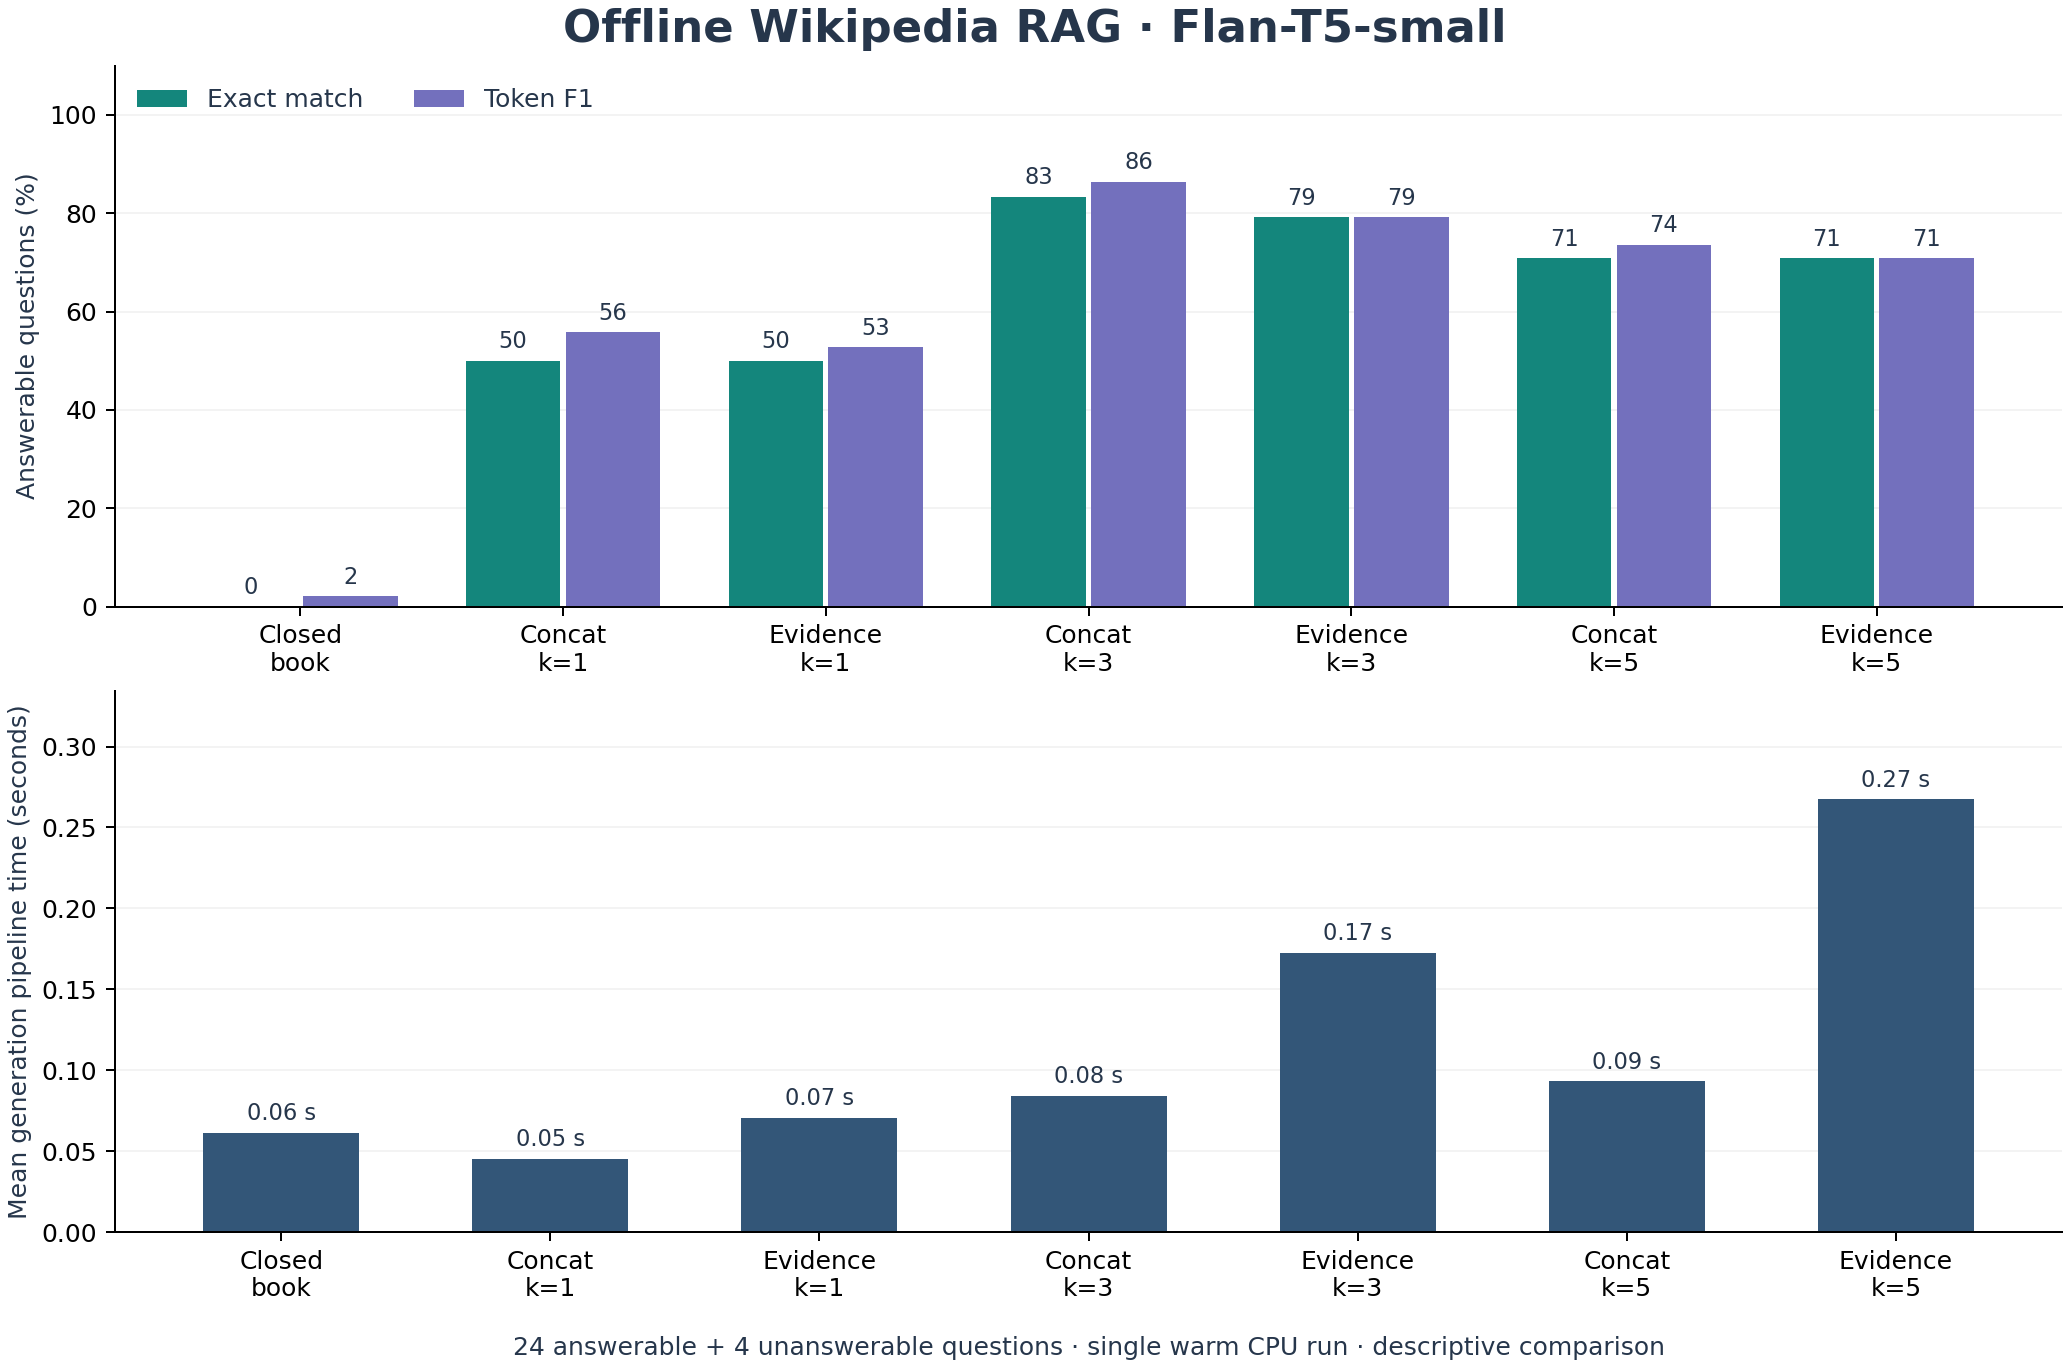

In [66]:
summary = pd.DataFrame(json.loads((result_dir / "summary.json").read_text()))
columns = ["method", "k", "answerable_em", "answerable_f1",
           "gold_passage_hit_at_k", "unanswerable_abstention_accuracy",
           "mean_latency_seconds", "mean_input_tokens", "mean_generation_calls"]
formats = {key: "{:.1%}" for key in columns if key in (
    "answerable_em", "answerable_f1", "gold_passage_hit_at_k",
    "unanswerable_abstention_accuracy"
)}
formats.update({"mean_latency_seconds": "{:.3f}",
                "mean_input_tokens": "{:.1f}", "mean_generation_calls": "{:.2f}"})
display(summary[columns].style.format(formats, na_rep="—"))
display(Image(filename=str(result_dir / "ablation.png"), width=1000))


In [67]:
predictions = read_jsonl(result_dir / "predictions.jsonl")
failures = [p for p in predictions if p["answerable"]
            and p["method"] != "closed_book" and p["em"] == 0]
display(pd.DataFrame([
    {"id": p["id"], "method": p["method"], "k": p["k"],
     "question": p["question"], "prediction": p["answer"],
     "gold": ", ".join(p["gold_answers"]),
     "gold_retrieved": p["gold_passage_hit"], "span_supported": p["span_supported"]}
    for p in failures[:10]
]))
best = summary[summary["method"] != "closed_book"].sort_values(
    ["answerable_f1", "answerable_em"], ascending=False
).iloc[0]
print(f"Highest observed RAG F1: {best['method']}, k={int(best['k'])}: "
      f"{best['answerable_f1']:.1%}; EM {best['answerable_em']:.1%}.")
assert len(predictions) == len(questions) * (1 + 2 * len(KS))
assert all(call["input_tokens"] <= 512 for p in predictions for call in p["trace"])
print("Verified", len(predictions), "predictions and all model input budgets.")
manifest = json.loads((result_dir / "run_manifest.json").read_text())
print("Python:", manifest["python"], "| Device:", manifest["device"])
print("Dataset revision:", manifest["dataset"]["revision"])
print("Model revision:", manifest["model"]["revision"])


,id,method,k,question,prediction,gold,gold_retrieved,span_supported
0,q01,concatenate,1,What is the atomic number of aluminium?,I don't know based on the provided evidence.,13,False,False
1,q01,generate_from_evidence,1,What is the atomic number of aluminium?,I don't know based on the provided evidence.,13,False,False
2,q01,generate_from_evidence,5,What is the atomic number of aluminium?,0,13,True,True
3,q02,concatenate,1,What is the capital of Alabama?,Huntsville,Montgomery,False,True
4,q02,generate_from_evidence,1,What is the capital of Alabama?,Huntsville,Montgomery,False,True
5,q03,concatenate,5,In which city was Aristotle born?,"Stagira, Chalcidice",Stagira,True,True
6,q04,concatenate,1,What philosophical system did Ayn Rand develop?,contemporary thought,Objectivism,False,True
7,q04,generate_from_evidence,1,What philosophical system did Ayn Rand develop?,contemporary thought,Objectivism,False,True
8,q05,concatenate,1,What is the capital of Algeria?,Geneva,Algiers,False,True
9,q05,generate_from_evidence,1,What is the capital of Algeria?,Geneva,Algiers,False,True


Highest observed RAG F1: concatenate, k=3: 86.4%; EM 83.3%.
Verified 196 predictions and all model input budgets.
Python: 3.13.12 | Device: cpu
Dataset revision: b04c8d1ceb2f5cd4588862100d08de323dccfbaa
Model revision: 0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab


## 10. Inline implementation checks and offline verification

These checks use functions defined in this notebook. The download checks use tiny temporary fixtures,
so rerunning them does not initiate a 71.79 GB transfer. The real-model check temporarily blocks Python
DNS and socket connection calls while loading the local model and answering with both fusion methods.


In [68]:
def run_inline_checks():
    checks = 0
    spec = dataset_inventory()
    assert len([e for e in spec["files"] if e["path"].endswith(".parquet")]) == 41
    checks += 1
    assert all(e["path"].startswith(CONFIG + "/") for e in spec["files"]
               if e["path"].endswith(".parquet"))
    assert sum(e["size"] for e in spec["files"] if e["path"].endswith(".parquet")) == 11630929031
    checks += 2
    article = {"id": "42", "title": "Aluminium", "url": "https://en.wikipedia.org/wiki/Aluminium",
               "text": "Aluminium is an element with atomic number 13. It is a metal."}
    assert span(article["text"], "13") == "13"
    assert span(article["text"], "3") is None
    assert span(article["text"], "13 metal") is None
    checks += 3
    with tempfile.TemporaryDirectory() as temp:
        directory = Path(temp)
        corpus = directory / "corpus.jsonl"
        corpus.write_text(json.dumps(article) + "\n")
        chunks = list(passages(article, chunk_words=6, overlap=2))
        assert all(article["text"][p["char_start"]:p["char_end"]] == p["text"] for p in chunks)
        assert chunks[-1]["char_end"] == len(article["text"])
        checks += 2
        build_index(corpus, directory / "index.sqlite")
        local_retriever = Retriever(directory / "index.sqlite")
        assert local_retriever.search("atomic number aluminium", 1)[0]["article_id"] == "42"
        assert not local_retriever.search("the and what", 3)
        local_retriever.close()
        checks += 2
        filename = directory / "tiny.parquet"
        filename.write_bytes(b"test data")
        tiny = {"repo_id": DATASET, "repo_type": "dataset", "revision": DATASET_REVISION,
                "files": [{"path": filename.name, "size": 9,
                           "sha256": hashlib.sha256(b"test data").hexdigest()}], "total_bytes": 9}
        # Subprocess creation is forbidden: a complete copy must return before any download code.
        with mock.patch.object(subprocess, "Popen", side_effect=AssertionError("Unexpected download")):
            ensure_local_snapshot(tiny, directory, allow_download=False, verify_hashes=True)
        checks += 1
        filename.write_bytes(b"bad")
        assert not snapshot_status(directory, tiny)["complete"]
        checks += 1
        filename.write_bytes(b"bad bytes")
        assert snapshot_status(directory, tiny)["complete"]
        assert not snapshot_status(directory, tiny, verify_hashes=True)["complete"]
        checks += 2
    assert scores("George Orwell", ["Orwell", "George Orwell"]) == (1.0, 1.0)
    assert scores("unknown", ["13"]) == (0.0, 0.0)
    checks += 2
    print(f"{checks} inline logic checks passed.")
    return checks

inline_checks_passed = run_inline_checks()


wikimedia/wikipedia: 1 local files complete. Download skipped; no network needed.
16 inline logic checks passed.


In [69]:
@contextmanager
def block_python_network():
    attempts = []
    def blocked(*args, **kwargs):
        attempts.append("network call")
        raise RuntimeError("Network disabled by notebook verification")
    with mock.patch.object(socket, "getaddrinfo", blocked), \
         mock.patch.object(socket, "gethostbyname", blocked), \
         mock.patch.object(socket, "create_connection", blocked), \
         mock.patch.object(socket.socket, "connect", blocked), \
         mock.patch.object(socket.socket, "connect_ex", blocked):
        yield attempts

with block_python_network() as network_attempts:
    offline_generator = Generator(MODEL_DIR, device=DEVICE, threads=THREADS)
    check_question = "What is the atomic number of aluminium?"
    check_hits = retriever.search(check_question, 3)
    offline_results = []
    for method in ("concatenate", "generate_from_evidence"):
        result = answer_question(offline_generator, check_question, check_hits, method)
        assert result["answer"] == "13" and result["citations"]
        assert all(call["input_tokens"] <= 512 for call in result["trace"])
        offline_results.append({"method": method, "answer": result["answer"],
                                "generation_calls": result["generation_calls"]})
    assert not network_attempts
    del offline_generator
verification = {"passed": True, "network_attempts": 0,
                "inline_logic_checks": inline_checks_passed, "real_model_checks": offline_results}
write_json(result_dir / "offline_verification.json", verification)
print(json.dumps(verification, indent=2))


{
  "passed": true,
  "network_attempts": 0,
  "inline_logic_checks": 16,
  "real_model_checks": [
    {
      "method": "concatenate",
      "answer": "13",
      "generation_calls": 1
    },
    {
      "method": "generate_from_evidence",
      "answer": "13",
      "generation_calls": 4
    }
  ]
}


## 11. Retrieval selection assessment

**Decision: retain BM25.** The tested semantic retriever uses
[`multi-qa-MiniLM-L6-cos-v1`](https://huggingface.co/sentence-transformers/multi-qa-MiniLM-L6-cos-v1),
attention-masked mean pooling, unit-normalized 384-dimensional embeddings, and exact
[FAISS](https://github.com/facebookresearch/faiss) cosine search. The index is persisted and reused;
its results were checked against direct cosine calculations. No embedding parameters were tuned on
the evaluation answers.

Both retrievers searched the same **500 articles / 26,568 passages**, including titles and text.
The Flan-T5 model, prompts, source-support guard, token budgets, and decoding were identical.
We evaluated **48 questions × 2 retrievers × 3 values of k × 2 fusion methods = 576 predictions**.
There are 40 answerable questions and eight unanswerable questions. The additional validation set
contains 16 answerable questions from 16 articles unused by the original questions, plus four
post-snapshot questions. It was constructed without inspecting either retriever's predictions.

These are **recorded comparison results**, distinct from the original 28-question ablation above.
They are embedded here so the notebook can be read independently. The reproducible experiment,
new questions, full predictions, and timing records are retained under the ignored local folder
`results/retrieval_comparison_20261023/`; normal Run All executes only the retained BM25 pipeline.

| Metric, averaged over the six matched settings | BM25 | Vector |
|---|---:|---:|
| Token F1, all 40 answerable questions | 68.94% | 67.81% |
| Exact match, all 40 answerable questions | 66.67% | 64.17% |
| Annotated passage hit@k | 74.17% | 65.00% |
| Correct abstention on eight unanswerable questions | 29.17% | 14.58% |
| Warm retrieval time, including query embedding | 2.84 ms | 6.56 ms |
| Token F1, original 24 answerable questions | 69.76% | 77.31% |
| Token F1, new 16 answerable questions | 67.71% | 53.54% |

Vectors improved on the original examples but lost that advantage on the new validation questions.
The pooled F1 difference (vector minus BM25) was **−1.13 percentage points**, with a paired
source-article bootstrap 95% interval of **[−11.02, +8.08] points**. The small sample therefore does
not establish that BM25 is universally superior. It provides insufficient evidence to replace the
working baseline, and the independent validation, passage-hit, abstention, and runtime results
all favour retaining it here.

The decision rule was fixed before the vector results: require at least a two-point F1 improvement,
a positive lower confidence bound, no aggregate EM/passage-hit/abstention decline, and no decline
on the new questions. None of those replacement conditions passed. The bootstrap resamples
**38 source articles**, keeping each article's questions and all six settings together, rather than
treating the 576 predictions as independent observations.

Across the combined answerable questions, the strongest observed BM25 setting was
**concatenate, k=3: F1 80.98%, exact match 77.50%**. The strongest vector setting was
**generate-from-evidence, k=5: F1 75.83%, exact match 75.00%**. Those are descriptive best rows;
the replacement decision uses the prespecified average across all six settings.

**Limitations:** this is one embedding model on a small convenience slice, not a global search for
the best retriever. All unanswerable examples ask about future events. Both approaches abstained
poorly on these examples: a copied phrase can be present in a source yet fail to answer the question.
The lexical support guard is not a factual-correctness guarantee. Gold passage annotations can
also omit alternative valid evidence.


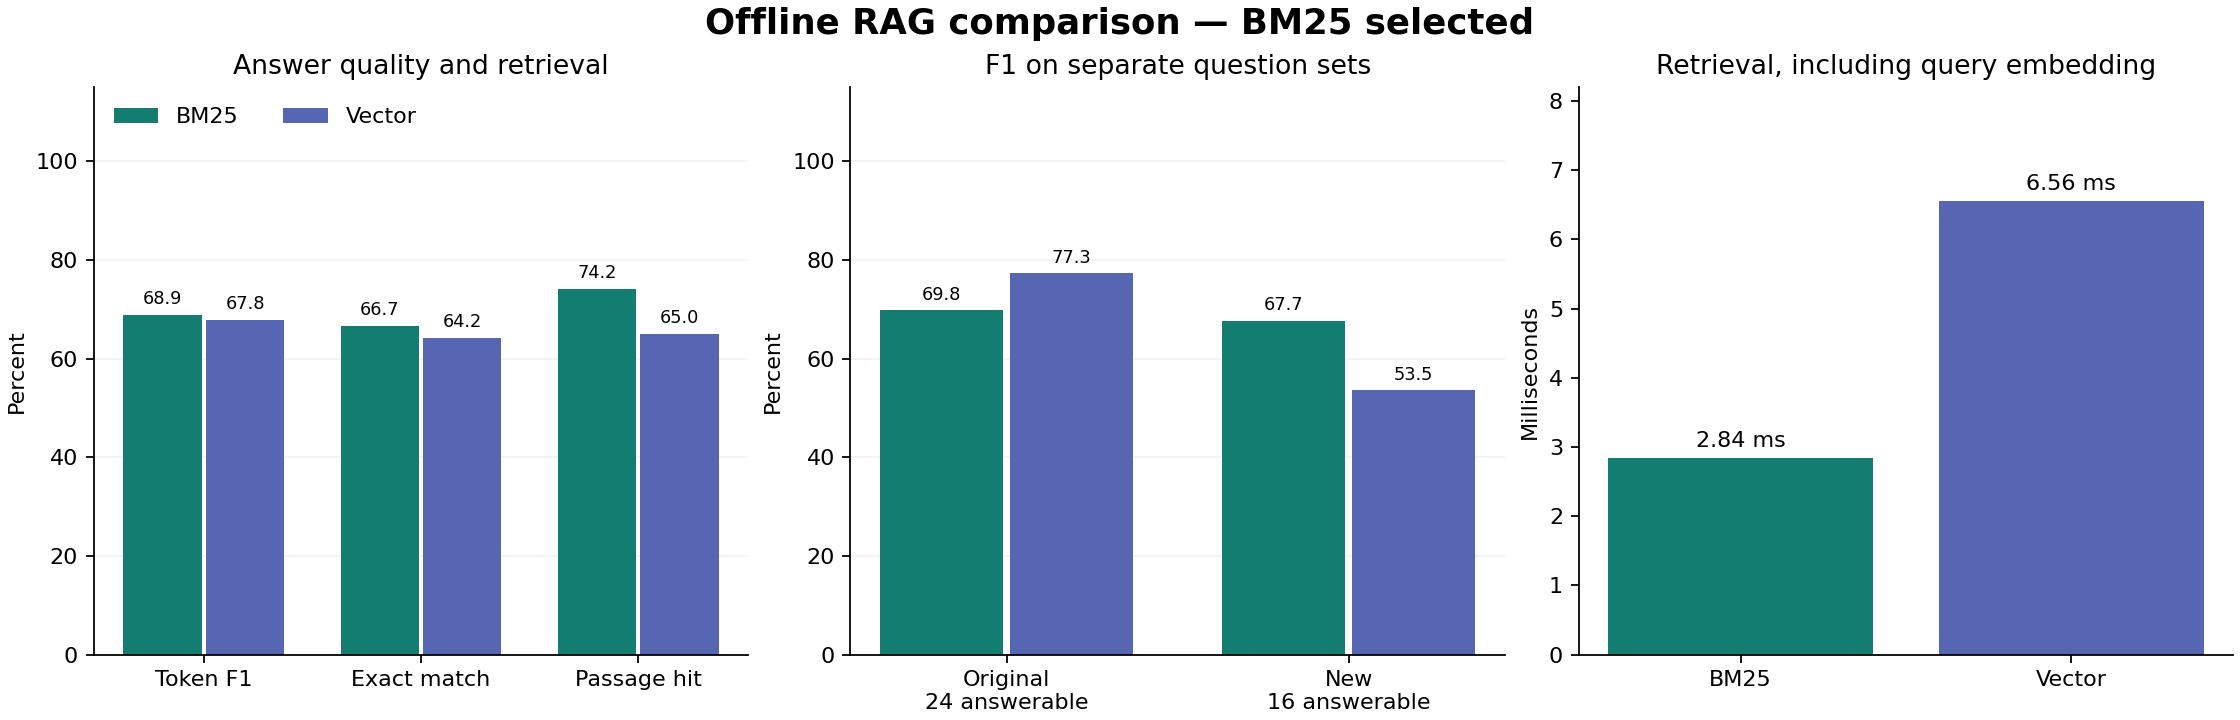

In [70]:
RETRIEVAL_ASSESSMENT = {'date': '2026-10-23',
 'decision': {'selected_retriever': 'bm25',
              'guards': {'f1_gain_at_least_2_points': False,
                         'paired_ci_positive': False,
                         'em_not_lower': False,
                         'passage_hit_not_lower': False,
                         'unanswerable_abstention_not_lower': False,
                         'independent_f1_not_lower': False},
              'f1_gain': -0.011338383838383814,
              'f1_gain_95_ci': [-0.11017686735778842, 0.08078463203463203],
              'source_article_clusters': 38,
              'aggregate': {'all': {'bm25': {'f1': 0.6893939393939393,
                                             'em': 0.6666666666666666,
                                             'gold_passage_hit': 0.7416666666666667,
                                             'unanswerable_abstention': 0.2916666666666667,
                                             'retrieval_seconds': 0.002842776021376873,
                                             'end_to_end_seconds': 0.13172677600411792},
                                    'vector': {'f1': 0.6780555555555555,
                                               'em': 0.6416666666666666,
                                               'gold_passage_hit': 0.6499999999999999,
                                               'unanswerable_abstention': 0.14583333333333334,
                                               'retrieval_seconds': 0.006557058145517658,
                                               'end_to_end_seconds': 0.13600767560066945}},
                            'original_development': {'bm25': {'f1': 0.6976010101010102,
                                                              'em': 0.6736111111111112,
                                                              'gold_passage_hit': 0.7361111111111112,
                                                              'unanswerable_abstention': 0.2916666666666667,
                                                              'retrieval_seconds': 0.002771502964606043,
                                                              'end_to_end_seconds': 0.1265431289469537},
                                                     'vector': {'f1': 0.7731481481481481,
                                                                'em': 0.7361111111111112,
                                                                'gold_passage_hit': 0.7083333333333333,
                                                                'unanswerable_abstention': 0.20833333333333334,
                                                                'retrieval_seconds': 0.006495385321094156,
                                                                'end_to_end_seconds': 0.13097245995812132}},
                            'independent_validation': {'bm25': {'f1': 0.6770833333333333,
                                                                'em': 0.65625,
                                                                'gold_passage_hit': 0.75,
                                                                'unanswerable_abstention': 0.2916666666666667,
                                                                'retrieval_seconds': 0.002942558300856035,
                                                                'end_to_end_seconds': 0.1389838818841478},
                                                       'vector': {'f1': 0.5354166666666667,
                                                                  'em': 0.5,
                                                                  'gold_passage_hit': 0.5625,
                                                                  'unanswerable_abstention': 0.08333333333333333,
                                                                  'retrieval_seconds': 0.006643400099710562,
                                                                  'end_to_end_seconds': 0.14305697750023683}}},
              'policy': {'primary': 'mean answerable token F1 across six '
                                    'matched fusion/k settings',
                         'minimum_f1_gain': 0.02,
                         'bootstrap_clusters': 'source article, paired across '
                                               'retrievers',
                         'bootstrap_replicates': 10000,
                         'bootstrap_seed': 42,
                         'required_ci_lower_bound': 0,
                         'other_guards': ['mean EM does not decline',
                                          'mean annotated passage hit over k '
                                          'does not decline',
                                          'unanswerable abstention does not '
                                          'decline',
                                          'independent new-question F1 does '
                                          'not decline'],
                         'fallback': 'bm25',
                         'frozen_before_dense_results': True,
                         'scope': 'one fixed QA embedding model, exact cosine '
                                  'search, no tuning on evaluation answers'},
              'claim_scope': 'This fixed model and small English corpus; not a '
                             'global optimum.'},
 'configurations': [{'evaluation_set': 'all',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 1,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.5765151515151515,
                     'em': 0.525,
                     'gold_passage_hit': 0.5,
                     'unanswerable_abstention': 0.375,
                     'retrieval_seconds': 0.002842776021376873,
                     'generation_seconds': 0.04718502508376332,
                     'end_to_end_seconds': 0.05002780110514019},
                    {'evaluation_set': 'all',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 1,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.5666666666666667,
                     'em': 0.55,
                     'gold_passage_hit': 0.5,
                     'unanswerable_abstention': 0.5,
                     'retrieval_seconds': 0.002842776021376873,
                     'generation_seconds': 0.07584494447867958,
                     'end_to_end_seconds': 0.07868772050005646},
                    {'evaluation_set': 'all',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 3,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.8098484848484848,
                     'em': 0.775,
                     'gold_passage_hit': 0.825,
                     'unanswerable_abstention': 0.125,
                     'retrieval_seconds': 0.002842776021376873,
                     'generation_seconds': 0.08595832372990724,
                     'end_to_end_seconds': 0.0888010997512841},
                    {'evaluation_set': 'all',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 3,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.725,
                     'em': 0.725,
                     'gold_passage_hit': 0.825,
                     'unanswerable_abstention': 0.375,
                     'retrieval_seconds': 0.002842776021376873,
                     'generation_seconds': 0.18300252345837484,
                     'end_to_end_seconds': 0.1858452994797517},
                    {'evaluation_set': 'all',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 5,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.7333333333333333,
                     'em': 0.7,
                     'gold_passage_hit': 0.9,
                     'unanswerable_abstention': 0.375,
                     'retrieval_seconds': 0.002842776021376873,
                     'generation_seconds': 0.09366879252092986,
                     'end_to_end_seconds': 0.09651156854230673},
                    {'evaluation_set': 'all',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 5,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.725,
                     'em': 0.725,
                     'gold_passage_hit': 0.9,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.002842776021376873,
                     'generation_seconds': 0.2876443906247914,
                     'end_to_end_seconds': 0.2904871666461683},
                    {'evaluation_set': 'all',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 1,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.6566666666666666,
                     'em': 0.6,
                     'gold_passage_hit': 0.425,
                     'unanswerable_abstention': 0.125,
                     'retrieval_seconds': 0.006557058145517658,
                     'generation_seconds': 0.04797099479189152,
                     'end_to_end_seconds': 0.05452805293740918},
                    {'evaluation_set': 'all',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 1,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.65,
                     'em': 0.6,
                     'gold_passage_hit': 0.425,
                     'unanswerable_abstention': 0.125,
                     'retrieval_seconds': 0.006557058145517658,
                     'generation_seconds': 0.08033042879242203,
                     'end_to_end_seconds': 0.08688748693793968},
                    {'evaluation_set': 'all',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 3,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.6916666666666667,
                     'em': 0.65,
                     'gold_passage_hit': 0.7,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.006557058145517658,
                     'generation_seconds': 0.0852325711046736,
                     'end_to_end_seconds': 0.09178962925019125},
                    {'evaluation_set': 'all',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 3,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.6333333333333333,
                     'em': 0.625,
                     'gold_passage_hit': 0.7,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.006557058145517658,
                     'generation_seconds': 0.18257128554159863,
                     'end_to_end_seconds': 0.18912834368711628},
                    {'evaluation_set': 'all',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 5,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.6783333333333333,
                     'em': 0.625,
                     'gold_passage_hit': 0.825,
                     'unanswerable_abstention': 0.125,
                     'retrieval_seconds': 0.006557058145517658,
                     'generation_seconds': 0.09068866495863404,
                     'end_to_end_seconds': 0.0972457231041517},
                    {'evaluation_set': 'all',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 5,
                     'answerable_n': 40,
                     'unanswerable_n': 8,
                     'f1': 0.7583333333333333,
                     'em': 0.75,
                     'gold_passage_hit': 0.825,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.006557058145517658,
                     'generation_seconds': 0.2899097595416909,
                     'end_to_end_seconds': 0.29646681768720856},
                    {'evaluation_set': 'original_development',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 1,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.5580808080808081,
                     'em': 0.5,
                     'gold_passage_hit': 0.4583333333333333,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.002771502964606043,
                     'generation_seconds': 0.04497313835781824,
                     'end_to_end_seconds': 0.047744641322424286},
                    {'evaluation_set': 'original_development',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 1,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.5277777777777778,
                     'em': 0.5,
                     'gold_passage_hit': 0.4583333333333333,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.002771502964606043,
                     'generation_seconds': 0.07163093449967814,
                     'end_to_end_seconds': 0.07440243746428418},
                    {'evaluation_set': 'original_development',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 3,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.8636363636363636,
                     'em': 0.8333333333333334,
                     'gold_passage_hit': 0.875,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.002771502964606043,
                     'generation_seconds': 0.08223245832232351,
                     'end_to_end_seconds': 0.08500396128692955},
                    {'evaluation_set': 'original_development',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 3,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.7916666666666666,
                     'em': 0.7916666666666666,
                     'gold_passage_hit': 0.875,
                     'unanswerable_abstention': 0.5,
                     'retrieval_seconds': 0.002771502964606043,
                     'generation_seconds': 0.17489635717824317,
                     'end_to_end_seconds': 0.17766786014284922},
                    {'evaluation_set': 'original_development',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 5,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.7361111111111112,
                     'em': 0.7083333333333334,
                     'gold_passage_hit': 0.875,
                     'unanswerable_abstention': 0.5,
                     'retrieval_seconds': 0.002771502964606043,
                     'generation_seconds': 0.0922568452143813,
                     'end_to_end_seconds': 0.09502834817898734},
                    {'evaluation_set': 'original_development',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 5,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.7083333333333334,
                     'em': 0.7083333333333334,
                     'gold_passage_hit': 0.875,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.002771502964606043,
                     'generation_seconds': 0.2766400223216416,
                     'end_to_end_seconds': 0.27941152528624763},
                    {'evaluation_set': 'original_development',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 1,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.7333333333333334,
                     'em': 0.6666666666666666,
                     'gold_passage_hit': 0.4583333333333333,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.006495385321094156,
                     'generation_seconds': 0.044945894356975,
                     'end_to_end_seconds': 0.051441279678069156},
                    {'evaluation_set': 'original_development',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 1,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.7333333333333334,
                     'em': 0.6666666666666666,
                     'gold_passage_hit': 0.4583333333333333,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.006495385321094156,
                     'generation_seconds': 0.07589721278600337,
                     'end_to_end_seconds': 0.08239259810709752},
                    {'evaluation_set': 'original_development',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 3,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.8194444444444444,
                     'em': 0.7916666666666666,
                     'gold_passage_hit': 0.7916666666666666,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.006495385321094156,
                     'generation_seconds': 0.08532908778605426,
                     'end_to_end_seconds': 0.0918244731071484},
                    {'evaluation_set': 'original_development',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 3,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.75,
                     'em': 0.75,
                     'gold_passage_hit': 0.7916666666666666,
                     'unanswerable_abstention': 0.5,
                     'retrieval_seconds': 0.006495385321094156,
                     'generation_seconds': 0.17513796421449765,
                     'end_to_end_seconds': 0.1816333495355918},
                    {'evaluation_set': 'original_development',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 5,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.7694444444444445,
                     'em': 0.7083333333333334,
                     'gold_passage_hit': 0.875,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.006495385321094156,
                     'generation_seconds': 0.08831880949998906,
                     'end_to_end_seconds': 0.09481419482108322},
                    {'evaluation_set': 'original_development',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 5,
                     'answerable_n': 24,
                     'unanswerable_n': 4,
                     'f1': 0.8333333333333334,
                     'em': 0.8333333333333334,
                     'gold_passage_hit': 0.875,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.006495385321094156,
                     'generation_seconds': 0.27723347917864366,
                     'end_to_end_seconds': 0.28372886449973783},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 1,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.6041666666666666,
                     'em': 0.5625,
                     'gold_passage_hit': 0.5625,
                     'unanswerable_abstention': 0.5,
                     'retrieval_seconds': 0.002942558300856035,
                     'generation_seconds': 0.05028166650008643,
                     'end_to_end_seconds': 0.053224224800942466},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 1,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.625,
                     'em': 0.625,
                     'gold_passage_hit': 0.5625,
                     'unanswerable_abstention': 0.75,
                     'retrieval_seconds': 0.002942558300856035,
                     'generation_seconds': 0.0817445584492816,
                     'end_to_end_seconds': 0.08468711675013765},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 3,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.7291666666666666,
                     'em': 0.6875,
                     'gold_passage_hit': 0.75,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.002942558300856035,
                     'generation_seconds': 0.09117453530052444,
                     'end_to_end_seconds': 0.09411709360138047},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 3,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.625,
                     'em': 0.625,
                     'gold_passage_hit': 0.75,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.002942558300856035,
                     'generation_seconds': 0.19435115625055915,
                     'end_to_end_seconds': 0.19729371455141517},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'bm25',
                     'method': 'concatenate',
                     'k': 5,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.7291666666666666,
                     'em': 0.6875,
                     'gold_passage_hit': 0.9375,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.002942558300856035,
                     'generation_seconds': 0.09564551875009783,
                     'end_to_end_seconds': 0.09858807705095388},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'bm25',
                     'method': 'generate_from_evidence',
                     'k': 5,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.75,
                     'em': 0.75,
                     'gold_passage_hit': 0.9375,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.002942558300856035,
                     'generation_seconds': 0.30305050624920116,
                     'end_to_end_seconds': 0.30599306455005715},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 1,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.5416666666666666,
                     'em': 0.5,
                     'gold_passage_hit': 0.375,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.006643400099710562,
                     'generation_seconds': 0.05220613540077466,
                     'end_to_end_seconds': 0.05884953550048522},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 1,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.525,
                     'em': 0.5,
                     'gold_passage_hit': 0.375,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.006643400099710562,
                     'generation_seconds': 0.08653693120140815,
                     'end_to_end_seconds': 0.09318033130111872},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 3,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.5,
                     'em': 0.4375,
                     'gold_passage_hit': 0.5625,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.006643400099710562,
                     'generation_seconds': 0.08509744775074068,
                     'end_to_end_seconds': 0.09174084785045125},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 3,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.4583333333333333,
                     'em': 0.4375,
                     'gold_passage_hit': 0.5625,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.006643400099710562,
                     'generation_seconds': 0.19297793539954,
                     'end_to_end_seconds': 0.19962133549925057},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'vector',
                     'method': 'concatenate',
                     'k': 5,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.5416666666666666,
                     'em': 0.5,
                     'gold_passage_hit': 0.75,
                     'unanswerable_abstention': 0.25,
                     'retrieval_seconds': 0.006643400099710562,
                     'generation_seconds': 0.094006462600737,
                     'end_to_end_seconds': 0.10064986270044755},
                    {'evaluation_set': 'independent_validation',
                     'retriever': 'vector',
                     'method': 'generate_from_evidence',
                     'k': 5,
                     'answerable_n': 16,
                     'unanswerable_n': 4,
                     'f1': 0.6458333333333334,
                     'em': 0.625,
                     'gold_passage_hit': 0.75,
                     'unanswerable_abstention': 0,
                     'retrieval_seconds': 0.006643400099710562,
                     'generation_seconds': 0.3076565520499571,
                     'end_to_end_seconds': 0.31429995214966766}],
 'corpus_sha256': 'f330955333cf88dd8f8e7607386f4d794a94c29a45a830bf3a10b53709ea470f',
 'questions_sha256': '34e69e91413a0a01cc1ff3009fa1b7baca13409f63a474d6771bed11a38e1d73',
 'embedding_revision': 'b207367332321f8e44f96e224ef15bc607f4dbf0',
 'generation_model': {'model': 'google/flan-t5-small',
                      'revision': '0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab',
                      'files': {'README.md': '6cc6dc3d056aaeda9549dc685ca51600d600ab5b87c73c12e7165d8eff6b0c51',
                                'config.json': '439aa0fecf5a5546a1def68b1fc45e538e2c94528ce805378daf091e2bf6e4de',
                                'generation_config.json': 'f5a1c7e2be8092018d8835128987edf0111637dd98e90599cc80310fef75d95a',
                                'model.safetensors': '495fa51e204676f1a857a9fc13c4c89f3f5ba9f480b898cebca02add25e6d749',
                                'special_tokens_map.json': '5c87151ef0f72a99d1f766a4c418bd2a1f90aaa30a8e22fe5eca9641daebb64f',
                                'spiece.model': 'd60acb128cf7b7f2536e8f38a5b18a05535c9e14c7a355904270e15b0945ea86',
                                'tokenizer.json': 'fe2ebbbbde2985be723e0ce18217853e4020c5e9d35bd07be2c27ab9d3ead57a',
                                'tokenizer_config.json': 'fcde0f79bffda3688119c94330866a8fbf8de20ae65a8c492c9bd47c704655a0'}}}

# Display the recorded measurements without downloading or loading a vector model.
assessment_table = pd.DataFrame(RETRIEVAL_ASSESSMENT["configurations"])
display(assessment_table[assessment_table["evaluation_set"] == "all"]
        [["retriever", "method", "k", "f1", "em", "gold_passage_hit",
          "unanswerable_abstention", "retrieval_seconds"]]
        .style.format({"f1":"{:.2%}", "em":"{:.2%}", "gold_passage_hit":"{:.2%}",
                       "unanswerable_abstention":"{:.2%}", "retrieval_seconds":"{:.4f}"}))
print("Retained retrieval:", RETRIEVAL_ASSESSMENT["decision"]["selected_retriever"])
if retriever.metadata["corpus_sha256"] != RETRIEVAL_ASSESSMENT["corpus_sha256"]:
    print("The current corpus differs from this recorded assessment; re-evaluate before transferring its conclusion.")


,retriever,method,k,f1,em,gold_passage_hit,unanswerable_abstention,retrieval_seconds
0,bm25,concatenate,1,57.65%,52.50%,50.00%,37.50%,0.0028
1,bm25,generate_from_evidence,1,56.67%,55.00%,50.00%,50.00%,0.0028
2,bm25,concatenate,3,80.98%,77.50%,82.50%,12.50%,0.0028
3,bm25,generate_from_evidence,3,72.50%,72.50%,82.50%,37.50%,0.0028
4,bm25,concatenate,5,73.33%,70.00%,90.00%,37.50%,0.0028
5,bm25,generate_from_evidence,5,72.50%,72.50%,90.00%,0.00%,0.0028
6,vector,concatenate,1,65.67%,60.00%,42.50%,12.50%,0.0066
7,vector,generate_from_evidence,1,65.00%,60.00%,42.50%,12.50%,0.0066
8,vector,concatenate,3,69.17%,65.00%,70.00%,25.00%,0.0066
9,vector,generate_from_evidence,3,63.33%,62.50%,70.00%,25.00%,0.0066


Retained retrieval: bm25


## Interpretation and attribution

The download covers the complete English subset; other languages are excluded.
The default index and the 28 development questions
cover the first 500 English articles, so their results do not represent all Wikipedia. Increasing k can
add distractors or shrink each visible excerpt. The evidence method costs additional model calls.
Lexical source matches support traceable citations but do not guarantee correct answers.

Wikipedia text is by Wikipedia contributors; article records retain original source URLs. Contributor
histories are available on each article's Wikipedia history page. The
[dataset card](https://huggingface.co/datasets/wikimedia/wikipedia) describes its
[CC-BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/) and
[GFDL](https://www.gnu.org/licenses/fdl-1.3.html) licensing. Local chunking and prompt packing create
excerpts and normalize whitespace. The [Flan-T5-small model](https://huggingface.co/google/flan-t5-small)
is distributed under Apache 2.0 and its original README is included in the model download.

References: [Hugging Face downloads](https://huggingface.co/docs/huggingface_hub/en/guides/download),
[SQLite FTS5 BM25](https://www.sqlite.org/fts5.html#the_bm25_function).
